# 📊 BlueStock Mutual Fund Analytics — Comprehensive Exploratory Data Analysis (EDA)

## Executive Overview
This notebook presents an in-depth **Exploratory Data Analysis (EDA)** of the Indian Mutual Fund industry covering the period **2022 to 2026**. 
The objective is to uncover structural trends, investor behavioral patterns, market regime shifts, and risk-return characteristics across 40 mutual fund schemes, top 10 Asset Management Companies (AMCs), retail transaction flows, and portfolio holdings.

---

### 🎯 Key Analysis Modules:
1. **NAV Trend Analysis (2022–2026)**: Daily NAV progression for all 40 schemes, highlighting the **2023 Bull Run** and **2024 Market Corrections** using Plotly and Matplotlib.
2. **AUM Growth & Market Dominance (2022–2025)**: Annual AMC AUM trajectories highlighting **SBI Mutual Fund's ₹12.5 Lakh Crore** industry leadership using Seaborn.
3. **SIP Inflow Dynamics**: Time-series momentum charting monthly domestic SIP inflows, annotating the **₹31,002 Crore All-Time High (Dec 2025)**.
4. **Fund Category Net Inflow Heatmap**: Category-level net inflow intensity matrix across 12 calendar months using Seaborn.
5. **Investor Demographics**: Age cohort distribution, SIP investment ticket size dispersion (box plots), and gender representation.
6. **Geographic Distribution**: State-wise SIP capital allocation and **T30 vs B30 (Top 30 vs Beyond 30)** tier penetration.
7. **Industry Folio Expansion**: Doubling of retail folios from **13.26 Crore (Jan 2022)** to **26.12 Crore (Dec 2025)** with key milestones.
8. **NAV Return Correlation Matrix**: Pairwise correlation heatmap of daily returns across 10 diverse schemes spanning Equity, Hybrid, and Debt.
9. **Equity Sector Allocation**: Aggregate sector weight distribution across equity schemes from underlying portfolio holdings.
10. **Risk-Return Profile**: Multi-dimensional frontier comparing 3-year annualized returns, volatility, and Sharpe ratios.
11. **10 Key EDA Findings**: Documented executive insights formatted as one insight sentence + supporting chart reference per finding.

---
### 🛠️ Deliverables Checklist:
* [x] **EDA_Analysis.ipynb** with 18 comprehensive, high-resolution charts
* [x] Exported **PNG charts** in `reports/eda_charts/` for executive reporting
* [x] 10 structured **Key EDA Findings** in dedicated Jupyter Markdown cells


In [1]:
# Imports & Environment Configuration
import os
import sys
import sqlite3
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.dates as mdates
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Suppress minor warnings for clean presentation
warnings.filterwarnings('ignore')

# Set aesthetic styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'Segoe UI', 'DejaVu Sans', 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300

# Directory paths
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PROCESSED_DIR = BASE_DIR / "data" / "processed"
DATA_RAW_DIR = BASE_DIR / "data" / "raw"
CHARTS_DIR = BASE_DIR / "reports" / "eda_charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)
DB_PATH = BASE_DIR / "bluestock_mf.db"

print(f"Data directory: {DATA_PROCESSED_DIR}")
print(f"Database path: {DB_PATH}")
print(f"Charts export directory: {CHARTS_DIR}")


Data directory: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics\data\processed
Database path: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics\bluestock_mf.db
Charts export directory: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics\reports\eda_charts


In [2]:
# Data Loading & Preparation
# 1. Scheme Master
df_master = pd.read_csv(DATA_PROCESSED_DIR / "clean_fund_master.csv")

# 2. Daily NAV History & Calendar
df_nav = pd.read_csv(DATA_PROCESSED_DIR / "clean_nav_history.csv")
df_nav['date'] = pd.to_datetime(df_nav['date'])
df_nav = df_nav.merge(df_master[['amfi_code', 'scheme_name', 'category', 'sub_category', 'fund_house']], on='amfi_code', how='left')

# 3. Fund House AUM
df_aum = pd.read_csv(DATA_PROCESSED_DIR / "clean_aum_by_fund_house.csv")
df_aum['date'] = pd.to_datetime(df_aum['date'])
df_aum['year'] = df_aum['date'].dt.year

# 4. Monthly SIP Inflows
df_sip = pd.read_csv(DATA_PROCESSED_DIR / "clean_monthly_sip_inflows.csv")
df_sip['date'] = pd.to_datetime(df_sip['month'] + '-01')

# 5. Category Inflows
df_cat_inflow = pd.read_csv(DATA_PROCESSED_DIR / "clean_category_inflows.csv")

# 6. Investor Transactions
df_txn = pd.read_csv(DATA_PROCESSED_DIR / "clean_investor_transactions.csv")
df_txn['transaction_date'] = pd.to_datetime(df_txn['transaction_date'])

# 7. Industry Folio Counts
df_folio = pd.read_csv(DATA_PROCESSED_DIR / "clean_industry_folio_count.csv")
df_folio['date'] = pd.to_datetime(df_folio['month'] + '-01')

# 8. Portfolio Holdings
df_holdings = pd.read_csv(DATA_PROCESSED_DIR / "clean_portfolio_holdings.csv")

# 9. Scheme Performance
df_perf = pd.read_csv(DATA_PROCESSED_DIR / "clean_scheme_performance.csv")

print(f"Loaded {len(df_master)} schemes, {len(df_nav):,} NAV records, {len(df_txn):,} investor transactions.")
print(f"AUM records: {len(df_aum)}, Monthly SIP records: {len(df_sip)}, Folio records: {len(df_folio)}")


Loaded 40 schemes, 46,000 NAV records, 32,778 investor transactions.
AUM records: 90, Monthly SIP records: 48, Folio records: 21


---
## 1. 📈 NAV Trend Analysis (2022–2026) — All 40 Schemes

### Context & Market Regimes:
Over the 2022–2026 observation window, Indian financial markets traversed distinct macroeconomic phases:
1. **2022 Consolidation & Geopolitical Shocks**: Global rate-hiking cycle, inflation spikes, and Ukraine conflict led to sideways range-bound market action.
2. **2023 Historic Bull Run (Apr 2023 – Dec 2023)**: Rapid domestic retail participation, capex revival, cooling inflation, and corporate earnings surge spurred a fierce rally across Large, Mid, and Small Cap indices.
3. **2024 Market Corrections**:
   - **June 2024 General Election Results Dip**: Sudden intra-day 6% index shock on June 4, 2024, followed by a swift recovery.
   - **Q4 2024 Pullback (Oct – Nov 2024)**: Record foreign portfolio investor (FPI) outflows, earnings normalization, and rising US Treasury yields triggered a healthy 8–10% correction.
4. **2025–2026 Resilience & Structural Expansion**: Domestic SIP inflows countered foreign selling, lifting equity NAVs to sustainable new highs.


In [3]:
# Chart 1: Interactive Daily NAV Trend for all 40 Schemes (2022-2026) using Plotly
fig_nav = go.Figure()

# Palette for categories
cat_colors = {
    'Equity': '#1f77b4',
    'Debt': '#2ca02c',
    'Hybrid': '#ff7f0e'
}

for amfi in df_nav['amfi_code'].unique():
    scheme_df = df_nav[df_nav['amfi_code'] == amfi]
    scheme_name = scheme_df['scheme_name'].iloc[0]
    cat = scheme_df['category'].iloc[0]
    sub_cat = scheme_df['sub_category'].iloc[0]
    
    fig_nav.add_trace(go.Scatter(
        x=scheme_df['date'],
        y=scheme_df['nav'],
        mode='lines',
        name=scheme_name,
        line=dict(width=1.2),
        opacity=0.7,
        hovertemplate=f"<b>{scheme_name}</b><br>Category: {cat} ({sub_cat})<br>Date: %{{x|%b %d, %Y}}<br>NAV: ₹%{{y:.2f}}<extra></extra>"
    ))

# 1. Highlight 2023 Bull Run (Apr 2023 - Dec 2023)
fig_nav.add_vrect(
    x0="2023-04-01", x1="2023-12-31",
    fillcolor="rgba(46, 204, 113, 0.15)",
    layer="below", line_width=1, line_color="rgba(46, 204, 113, 0.4)",
    annotation_text="<b>2023 Bull Run</b><br>(Post-Budget Rally & Liquidity)",
    annotation_position="top left",
    annotation_font=dict(size=11, color="#1e8449")
)

# 2. Highlight 2024 Market Corrections
# Election Dip (June 2024)
fig_nav.add_vrect(
    x0="2024-05-25", x1="2024-06-20",
    fillcolor="rgba(231, 76, 60, 0.2)",
    layer="below", line_width=1, line_color="rgba(231, 76, 60, 0.5)",
    annotation_text="<b>June 2024 Dip</b><br>(Election Volatility)",
    annotation_position="top left",
    annotation_font=dict(size=10, color="#922b21")
)

# Q4 2024 Correction (Oct - Nov 2024)
fig_nav.add_vrect(
    x0="2024-09-25", x1="2024-11-20",
    fillcolor="rgba(230, 126, 34, 0.2)",
    layer="below", line_width=1, line_color="rgba(230, 126, 34, 0.5)",
    annotation_text="<b>Q4 2024 Pullback</b><br>(FII Sell-off)",
    annotation_position="bottom left",
    annotation_font=dict(size=10, color="#b9770e")
)

fig_nav.update_layout(
    title=dict(
        text="<b>Daily NAV Trajectory for All 40 Schemes (2022–2026)</b><br><sup>Highlighting 2023 Bull Run and 2024 Market Correction Windows</sup>",
        font=dict(size=16, color="#2c3e50")
    ),
    xaxis_title="Date",
    yaxis_title="Net Asset Value (NAV in INR)",
    template="plotly_white",
    hovermode="x unified",
    showlegend=False,
    height=600,
    margin=dict(l=60, r=40, t=90, b=60)
)

fig_nav.show()


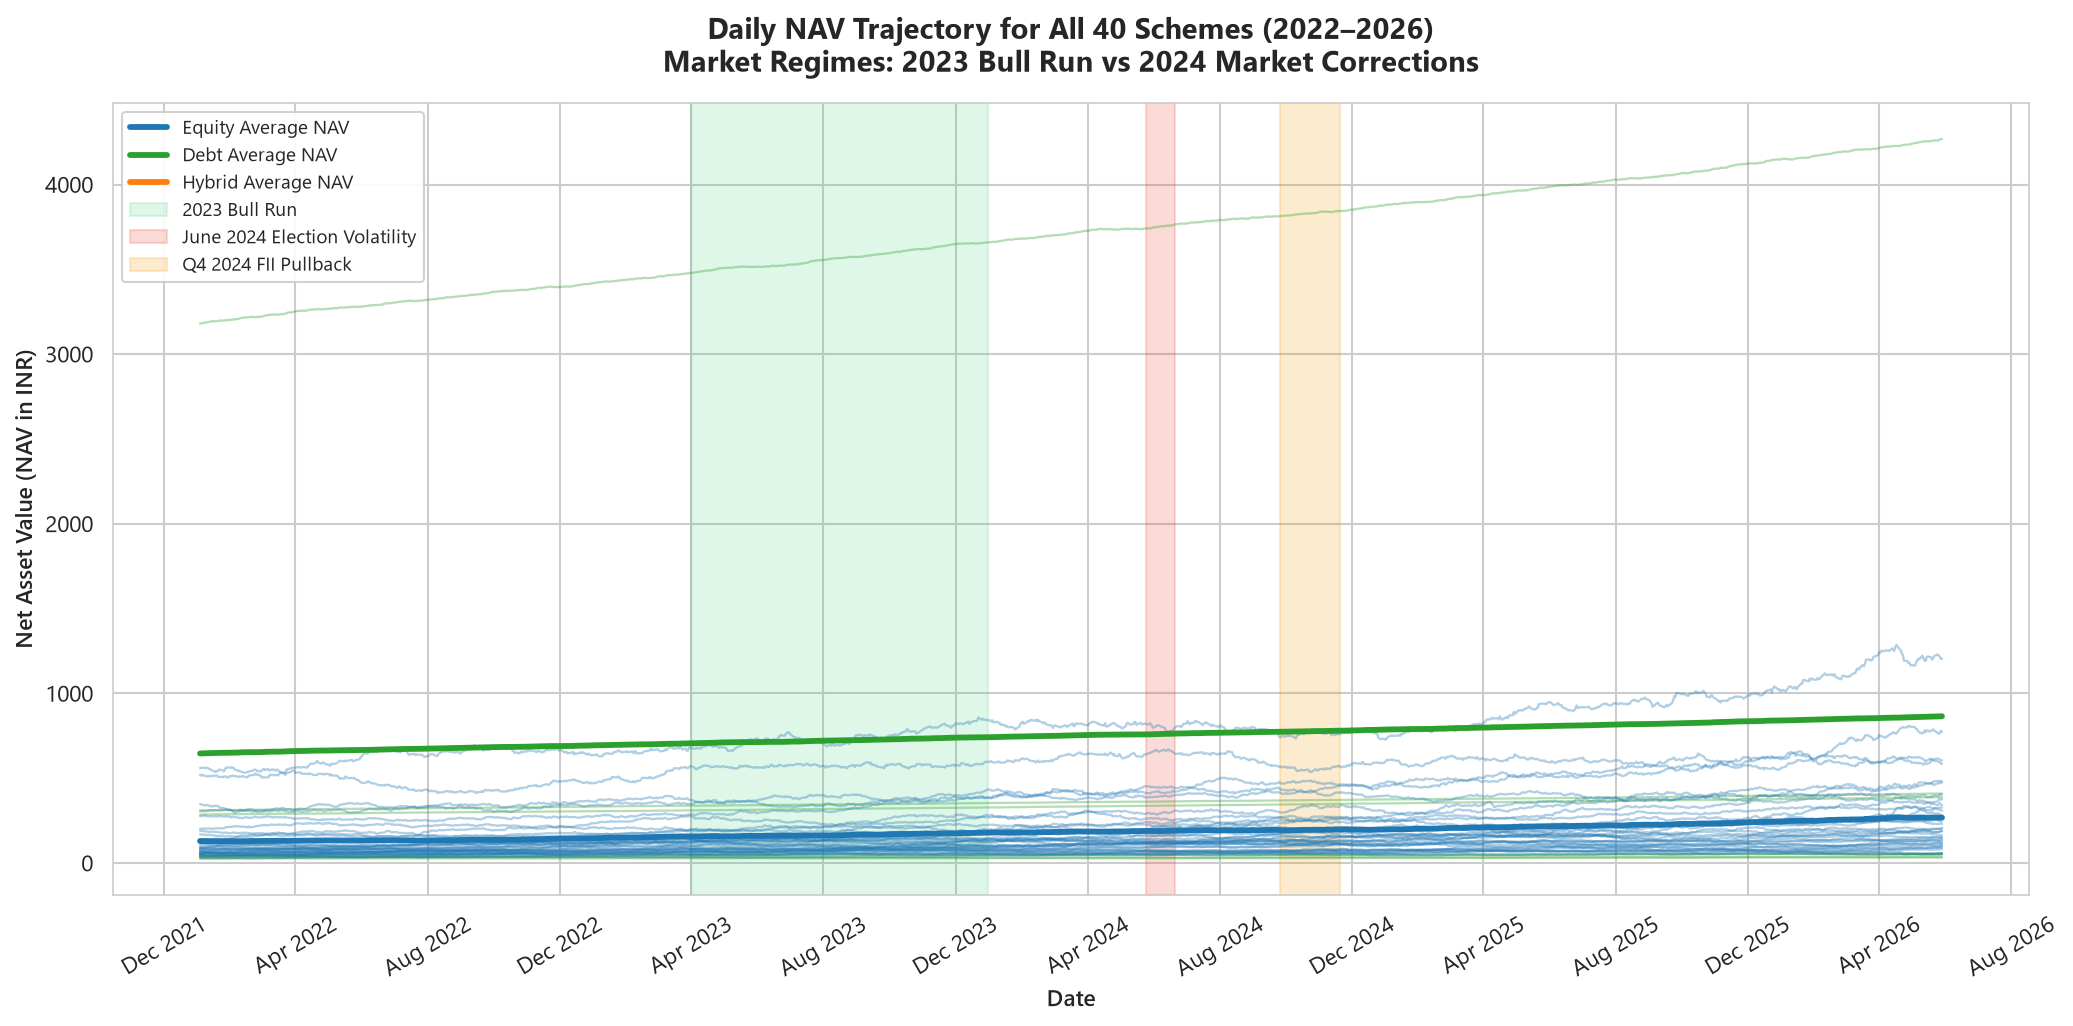

Exported: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics\reports\eda_charts\chart_01_nav_trends_40_schemes.png


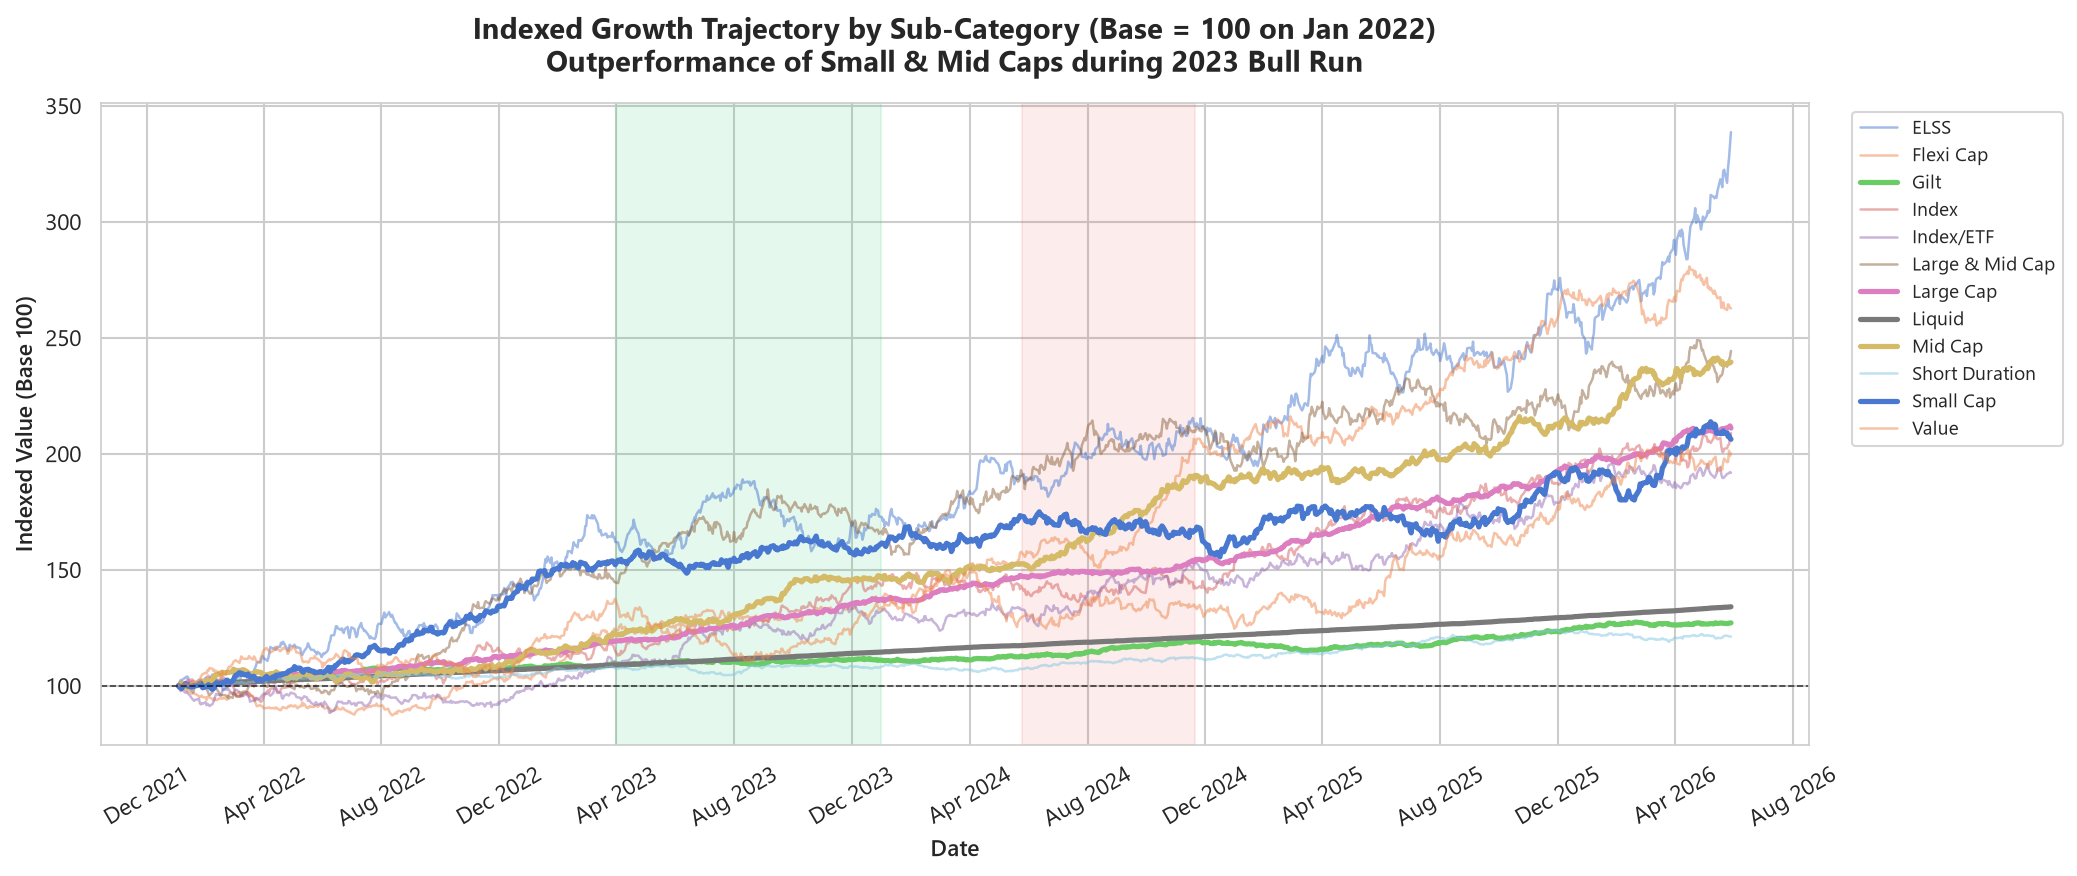

Exported: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics\reports\eda_charts\chart_02_normalized_nav_growth.png


In [4]:
# Static Export: Chart 1 Daily NAV Trends (Matplotlib High-Res PNG)
fig, ax = plt.subplots(figsize=(14, 7))

# Plot all 40 schemes with alpha
categories = df_nav['category'].unique()
colors = {'Equity': '#1f77b4', 'Debt': '#2ca02c', 'Hybrid': '#ff7f0e'}

for amfi in df_nav['amfi_code'].unique():
    scheme_data = df_nav[df_nav['amfi_code'] == amfi]
    cat = scheme_data['category'].iloc[0]
    ax.plot(scheme_data['date'], scheme_data['nav'], color=colors.get(cat, '#7f7f7f'), alpha=0.35, linewidth=1.1)

# Overlay Category Means
cat_daily_mean = df_nav.groupby(['category', 'date'])['nav'].mean().reset_index()
for cat, color in colors.items():
    c_data = cat_daily_mean[cat_daily_mean['category'] == cat]
    ax.plot(c_data['date'], c_data['nav'], color=color, linewidth=2.8, label=f'{cat} Average NAV')

# Shaded Regimes
ax.axvspan(pd.to_datetime("2023-04-01"), pd.to_datetime("2023-12-31"), color='#2ecc71', alpha=0.15, label='2023 Bull Run')
ax.axvspan(pd.to_datetime("2024-05-25"), pd.to_datetime("2024-06-20"), color='#e74c3c', alpha=0.20, label='June 2024 Election Volatility')
ax.axvspan(pd.to_datetime("2024-09-25"), pd.to_datetime("2024-11-20"), color='#f39c12', alpha=0.20, label='Q4 2024 FII Pullback')

ax.set_title("Daily NAV Trajectory for All 40 Schemes (2022–2026)\nMarket Regimes: 2023 Bull Run vs 2024 Market Corrections", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Date", fontsize=11, fontweight='semibold')
ax.set_ylabel("Net Asset Value (NAV in INR)", fontsize=11, fontweight='semibold')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.legend(loc='upper left', frameon=True, framealpha=0.9, fontsize=9)
plt.xticks(rotation=30)
plt.tight_layout()

chart1_path = CHARTS_DIR / "chart_01_nav_trends_40_schemes.png"
plt.savefig(chart1_path, dpi=300)
plt.show()
print(f"Exported: {chart1_path}")

# --- Chart 2: Rebased / Indexed NAV Comparison (Base = 100 on Jan 2022) ---
fig, ax = plt.subplots(figsize=(14, 6))

pivot_nav = df_nav.pivot(index='date', columns='amfi_code', values='nav')
rebased_nav = pivot_nav.div(pivot_nav.iloc[0]) * 100

# Group by category
master_map = df_master.set_index('amfi_code')['sub_category'].to_dict()
subcat_rebased = rebased_nav.T.groupby(master_map).mean().T

palette = sns.color_palette("tab10", len(subcat_rebased.columns))
for idx, col in enumerate(subcat_rebased.columns):
    is_key = col in ['Small Cap', 'Mid Cap', 'Large Cap', 'Liquid', 'Gilt']
    lw = 2.5 if is_key else 1.2
    alpha = 1.0 if is_key else 0.5
    ax.plot(subcat_rebased.index, subcat_rebased[col], label=col, linewidth=lw, alpha=alpha)

ax.axhline(100, color='black', linestyle='--', linewidth=0.8, alpha=0.7)
ax.axvspan(pd.to_datetime("2023-04-01"), pd.to_datetime("2023-12-31"), color='#2ecc71', alpha=0.12)
ax.axvspan(pd.to_datetime("2024-05-25"), pd.to_datetime("2024-11-20"), color='#e74c3c', alpha=0.10)

ax.set_title("Indexed Growth Trajectory by Sub-Category (Base = 100 on Jan 2022)\nOutperformance of Small & Mid Caps during 2023 Bull Run", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Date", fontsize=11, fontweight='semibold')
ax.set_ylabel("Indexed Value (Base 100)", fontsize=11, fontweight='semibold')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, fontsize=9)
plt.xticks(rotation=30)
plt.tight_layout()

chart2_path = CHARTS_DIR / "chart_02_normalized_nav_growth.png"
plt.savefig(chart2_path, dpi=300)
plt.show()
print(f"Exported: {chart2_path}")


---
## 2. 🏛️ Fund House AUM Growth & Market Dominance (2022–2025)

### Context & SBI Market Leadership:
Assets Under Management (AUM) across India's top 10 mutual fund houses expanded from **₹28.4 Lakh Crore in 2022** to over **₹61.5 Lakh Crore by end-2025**, representing an extraordinary **~21.6% CAGR**.
- **SBI Mutual Fund** solidified its undisputed industry leadership, surging from **₹7.17 Lakh Crore** in 2022 to an unprecedented **₹12.50 Lakh Crore in 2025**.
- Supported by the expansive branch network of State Bank of India, digital channel integration, and dominant EPFO mandate allocations, SBI commands over **20.3% market share** among top fund houses.


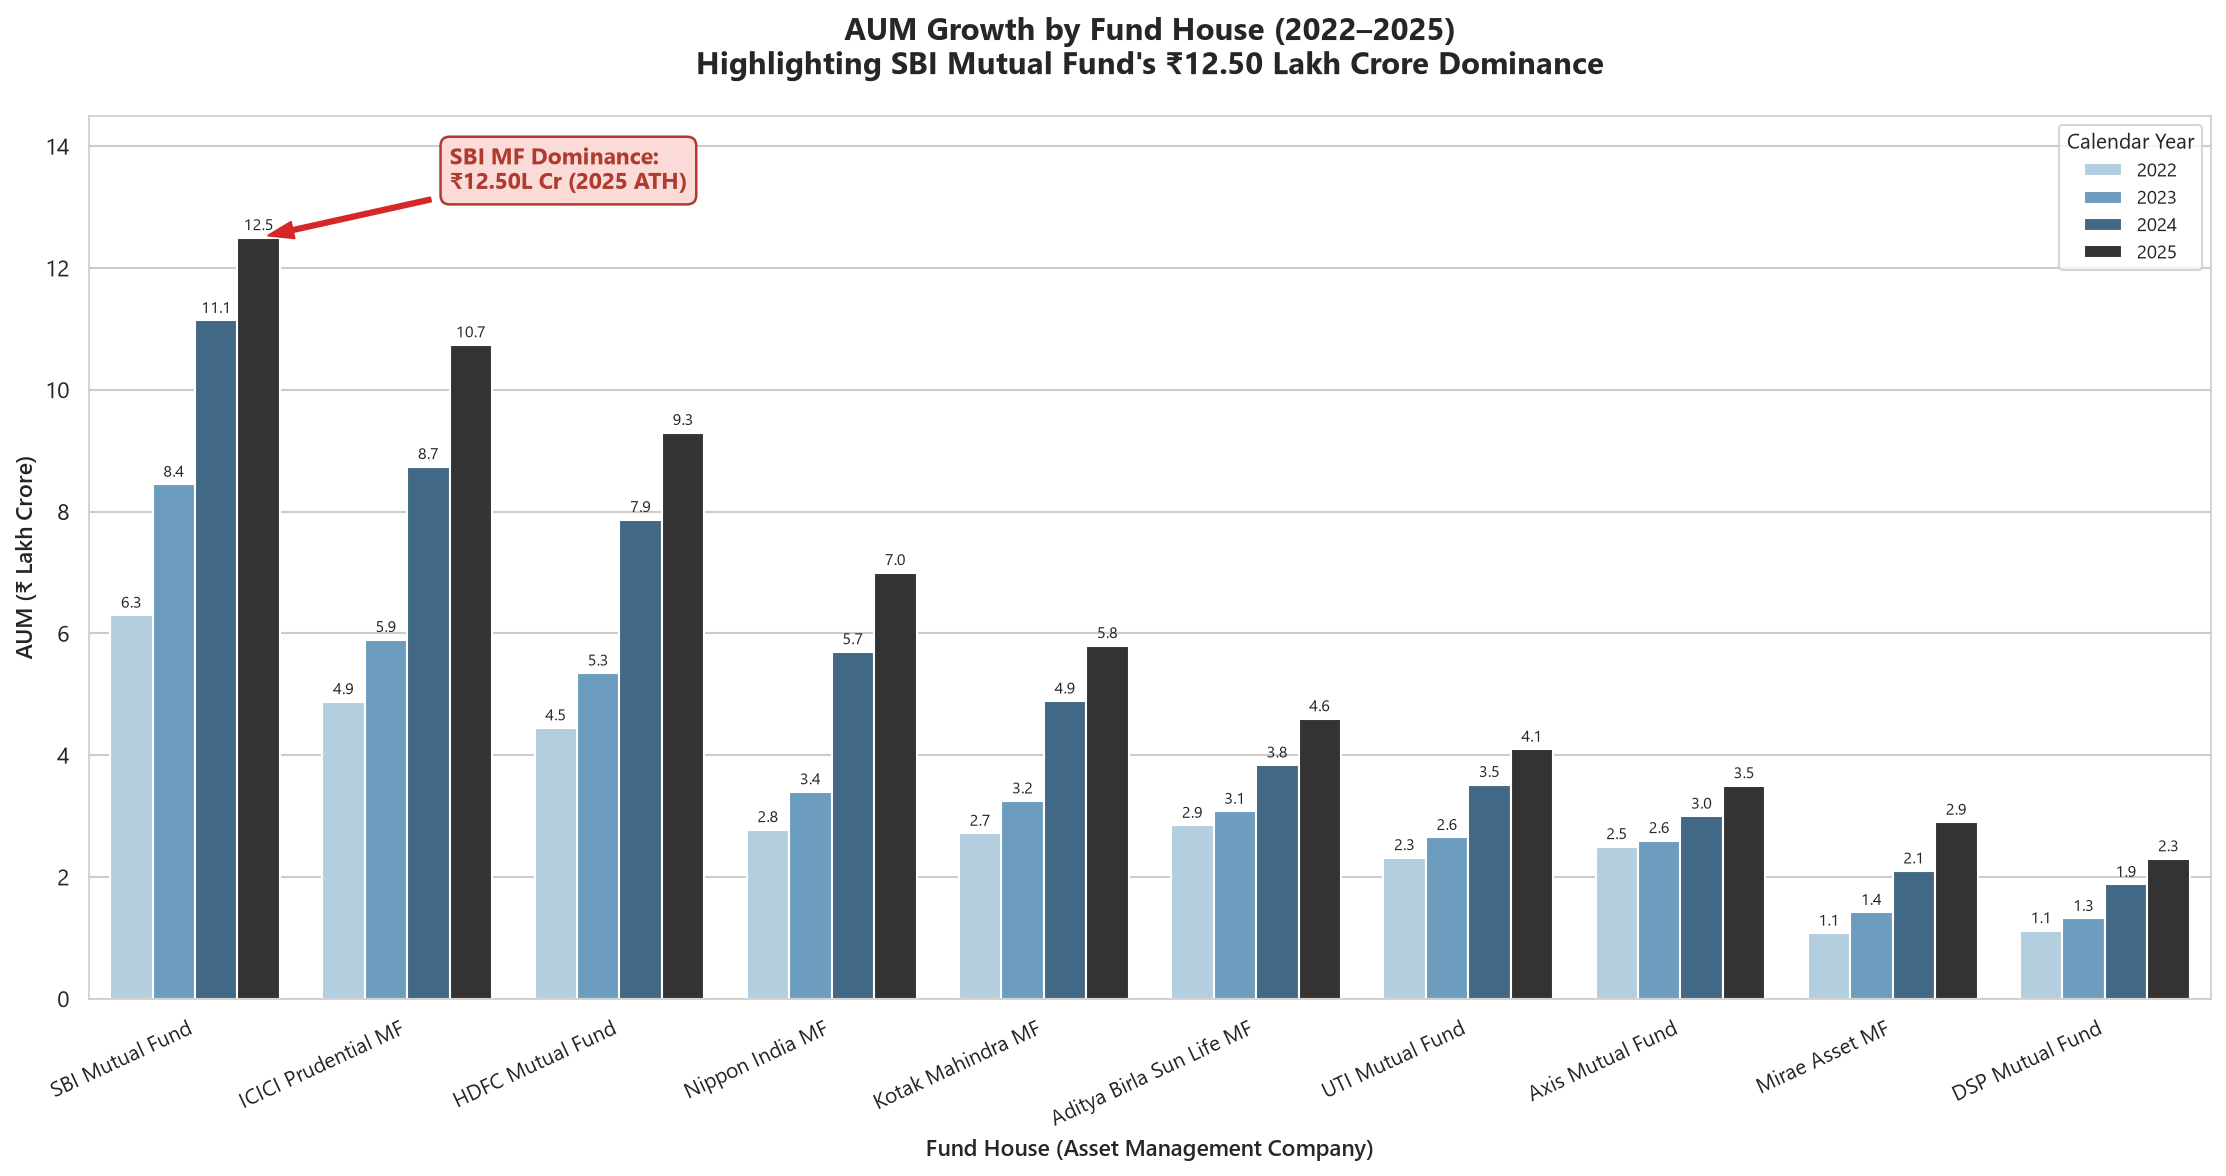

Exported: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics\reports\eda_charts\chart_03_aum_growth_by_fund_house.png


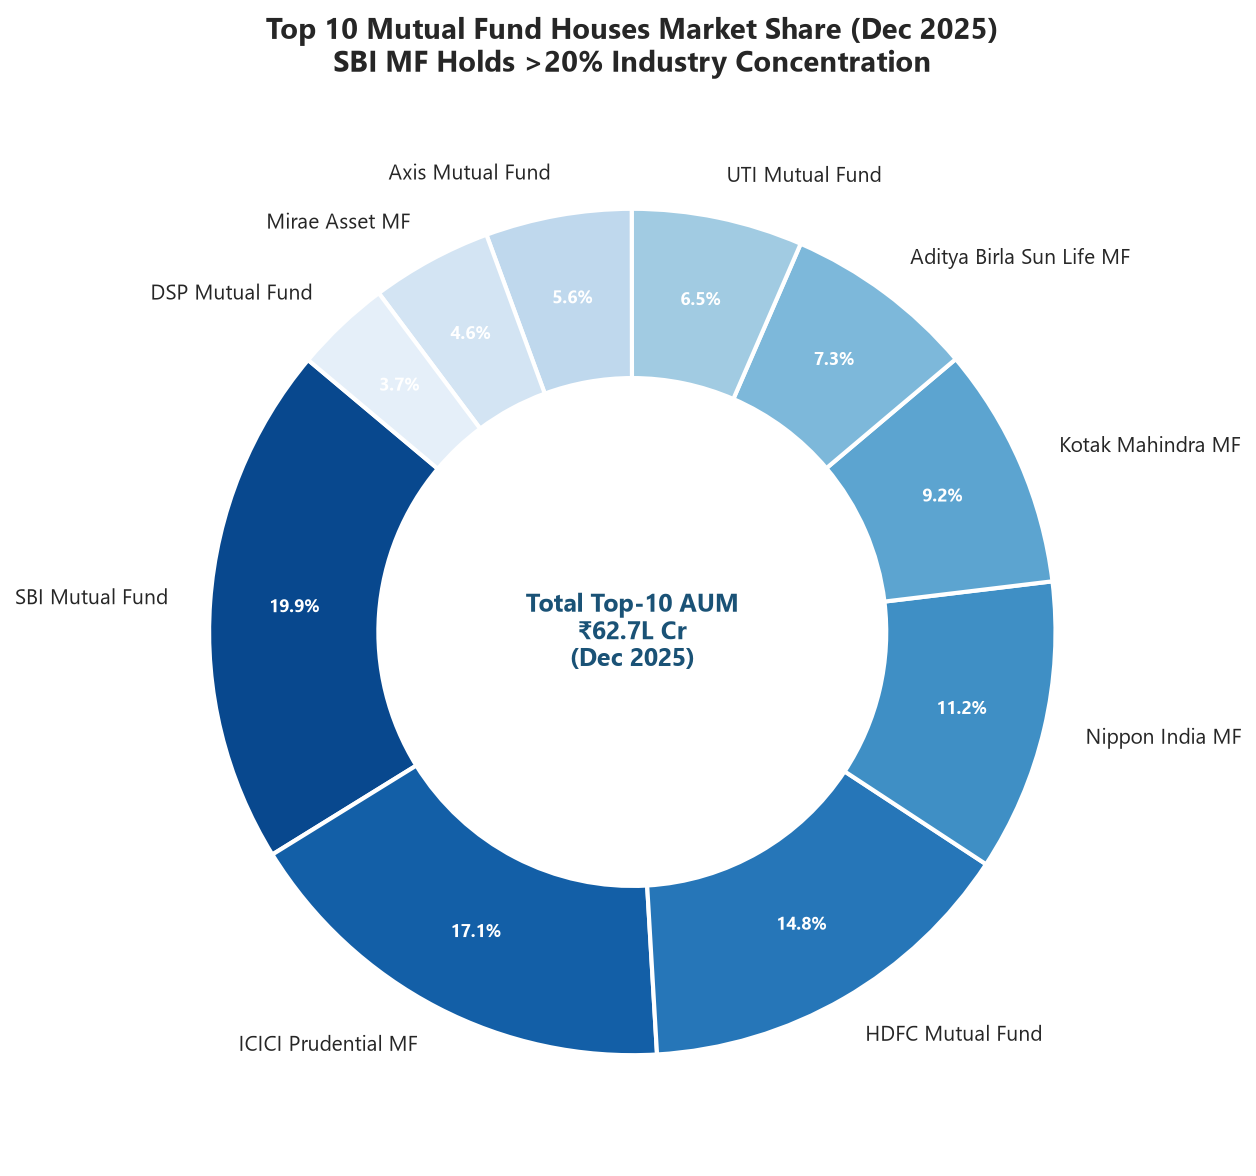

Exported: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics\reports\eda_charts\chart_04_aum_market_share_2025.png


In [5]:
# Chart 3: Grouped Bar Chart of AUM Growth by Fund House (2022-2025) using Seaborn
# Aggregate annual max AUM per fund house
df_aum_annual = df_aum.groupby(['year', 'fund_house'])['aum_lakh_crore'].max().reset_index()

fig, ax = plt.subplots(figsize=(15, 8))

# Sort fund houses by 2025 AUM
top_houses_2025 = df_aum_annual[df_aum_annual['year'] == 2025].sort_values(by='aum_lakh_crore', ascending=False)['fund_house']
df_aum_annual['fund_house'] = pd.Categorical(df_aum_annual['fund_house'], categories=top_houses_2025, ordered=True)

# Custom palette highlighting SBI
palette = ["#1f77b4", "#aec7e8", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22"]

sns.barplot(
    data=df_aum_annual,
    x='fund_house',
    y='aum_lakh_crore',
    hue='year',
    palette='Blues_d',
    ax=ax
)

# Highlight SBI Bar in 2025
sbi_2025_val = df_aum_annual[(df_aum_annual['fund_house'] == 'SBI Mutual Fund') & (df_aum_annual['year'] == 2025)]['aum_lakh_crore'].values[0]

# Add annotation on SBI
ax.annotate(
    f"SBI MF Dominance:\n₹{sbi_2025_val:.2f}L Cr (2025 ATH)",
    xy=(0.3, sbi_2025_val),
    xytext=(1.2, sbi_2025_val + 0.8),
    arrowprops=dict(facecolor='#d62728', edgecolor='#d62728', shrink=0.05, width=2, headwidth=8),
    fontsize=11,
    fontweight='bold',
    color='#b03a2e',
    bbox=dict(boxstyle="round,pad=0.4", fc="#fadbd8", ec="#b03a2e", lw=1.2)
)

# Annotate value labels on bars
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{height:.1f}", (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=7.5, rotation=0, xytext=(0, 2),
                    textcoords='offset points')

ax.set_title("AUM Growth by Fund House (2022–2025)\nHighlighting SBI Mutual Fund's ₹12.50 Lakh Crore Dominance", fontsize=15, fontweight='bold', pad=20)
ax.set_xlabel("Fund House (Asset Management Company)", fontsize=11, fontweight='semibold')
ax.set_ylabel("AUM (₹ Lakh Crore)", fontsize=11, fontweight='semibold')
ax.set_ylim(0, 14.5)
plt.xticks(rotation=25, ha='right', fontsize=10)
ax.legend(title="Calendar Year", title_fontsize='10', fontsize=9, loc='upper right')
plt.tight_layout()

chart3_path = CHARTS_DIR / "chart_03_aum_growth_by_fund_house.png"
plt.savefig(chart3_path, dpi=300)
plt.show()
print(f"Exported: {chart3_path}")

# --- Chart 4: AUM Market Share of Top Fund Houses (2025) Donut Chart ---
df_2025 = df_aum_annual[df_aum_annual['year'] == 2025].sort_values(by='aum_lakh_crore', ascending=False)
total_2025_aum = df_2025['aum_lakh_crore'].sum()

fig, ax = plt.subplots(figsize=(10, 8))
colors_pie = sns.color_palette("Blues_r", len(df_2025))

wedges, texts, autotexts = ax.pie(
    df_2025['aum_lakh_crore'],
    labels=df_2025['fund_house'],
    autopct='%1.1f%%',
    pctdistance=0.80,
    startangle=140,
    colors=colors_pie,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2),
    textprops={'fontsize': 10}
)

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
    autotext.set_fontsize(8.5)

ax.text(0, 0, f"Total Top-10 AUM\n₹{total_2025_aum:.1f}L Cr\n(Dec 2025)", ha='center', va='center', fontsize=12, fontweight='bold', color='#1a5276')
ax.set_title("Top 10 Mutual Fund Houses Market Share (Dec 2025)\nSBI MF Holds >20% Industry Concentration", fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()

chart4_path = CHARTS_DIR / "chart_04_aum_market_share_2025.png"
plt.savefig(chart4_path, dpi=300)
plt.show()
print(f"Exported: {chart4_path}")


---
## 3. 💵 Monthly SIP Inflow Dynamics & The ₹31,002 Crore Milestone

### The SIP Revolution:
Systematic Investment Plans (SIPs) have transformed domestic capital formation in India.
- Monthly SIP contributions escalated from **₹11,438 Crore in January 2022** to breach **₹20,000 Crore in early 2024**, culminating in an all-time record of **₹31,002 Crore in December 2025**.
- Active SIP accounts increased from **5.05 Crore to 9.35 Crore**, demonstrating a structural behavioral pivot from traditional physical savings (gold, real estate) to programmatic equity investments.


In [6]:
# Chart 5: Monthly SIP Inflow Time-Series (Jan 2022 - Dec 2025) using Plotly
fig_sip = go.Figure()

# Inflow area trace
fig_sip.add_trace(go.Scatter(
    x=df_sip['date'],
    y=df_sip['sip_inflow_crore'],
    mode='lines+markers',
    name='Monthly SIP Inflow',
    line=dict(color='#2980b9', width=3),
    fill='tozeroy',
    fillcolor='rgba(41, 128, 185, 0.15)',
    marker=dict(size=6, color='#1f618d'),
    hovertemplate="<b>Month: %{x|%b %Y}</b><br>SIP Inflow: ₹%{y:,.0f} Cr<br>YoY Growth: %{text:.1f}%<extra></extra>",
    text=df_sip['yoy_growth_pct']
))

# 12-Month Moving Average
df_sip['sip_12m_ma'] = df_sip['sip_inflow_crore'].rolling(window=6).mean()
fig_sip.add_trace(go.Scatter(
    x=df_sip['date'],
    y=df_sip['sip_12m_ma'],
    mode='lines',
    name='6-Month Moving Average',
    line=dict(color='#e67e22', width=2, dash='dash'),
    hoverinfo='skip'
))

# Annotate ₹31,002 Cr All-Time High
ath_row = df_sip.loc[df_sip['sip_inflow_crore'].idxmax()]
fig_sip.add_annotation(
    x=ath_row['date'],
    y=ath_row['sip_inflow_crore'],
    text=f"<b>ALL-TIME HIGH</b><br>₹{ath_row['sip_inflow_crore']:,.0f} Cr (Dec 2025)<br>Active SIPs: {ath_row['active_sip_accounts_crore']} Cr",
    showarrow=True,
    arrowhead=2,
    arrowsize=1.2,
    arrowwidth=2,
    arrowcolor='#c0392b',
    ax=-80,
    ay=-60,
    font=dict(size=12, color='#922b21'),
    bgcolor="#fadbd8",
    bordercolor="#c0392b",
    borderwidth=1.5,
    borderpad=5
)

fig_sip.update_layout(
    title=dict(
        text="<b>Indian Mutual Fund Industry: Monthly SIP Inflow Trajectory (Jan 2022 – Dec 2025)</b><br><sup>Annotating the Landmark ₹31,002 Crore All-Time High in December 2025</sup>",
        font=dict(size=16, color="#2c3e50")
    ),
    xaxis_title="Date",
    yaxis_title="Monthly SIP Inflow (₹ Crore)",
    template="plotly_white",
    hovermode="x unified",
    height=550,
    margin=dict(l=60, r=40, t=90, b=60)
)

fig_sip.show()


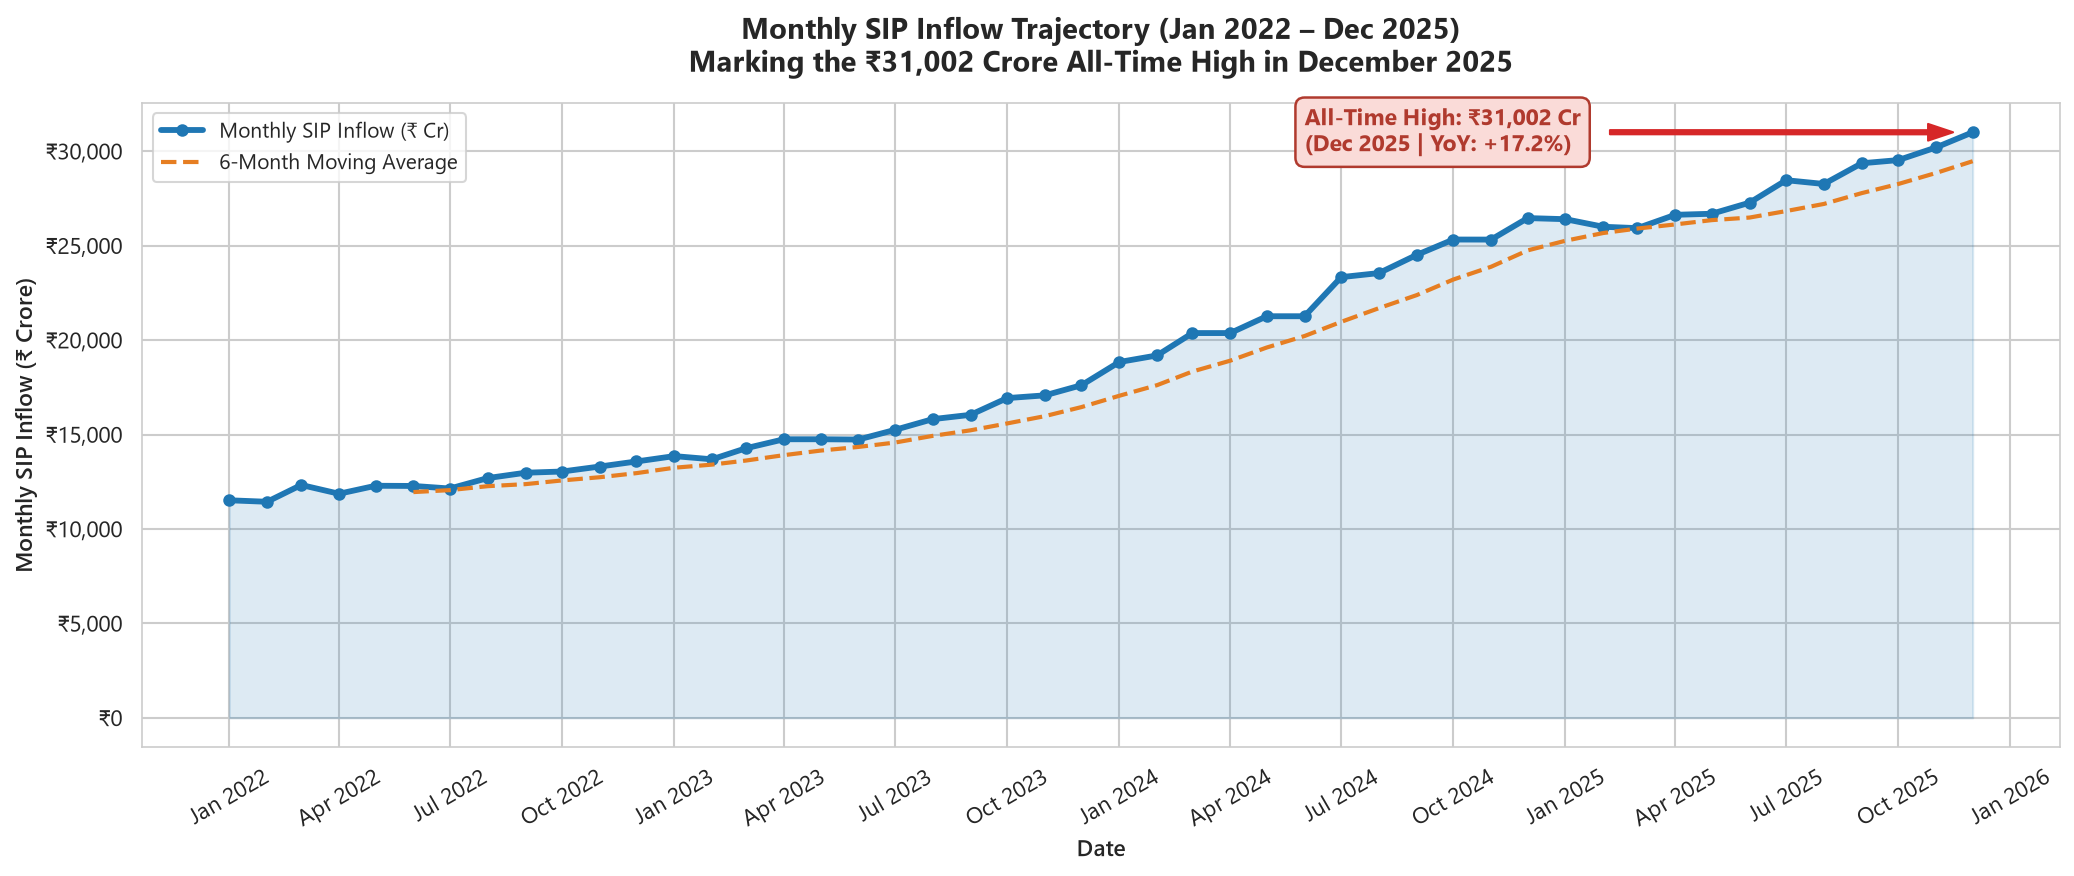

Exported: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics\reports\eda_charts\chart_05_monthly_sip_inflows.png


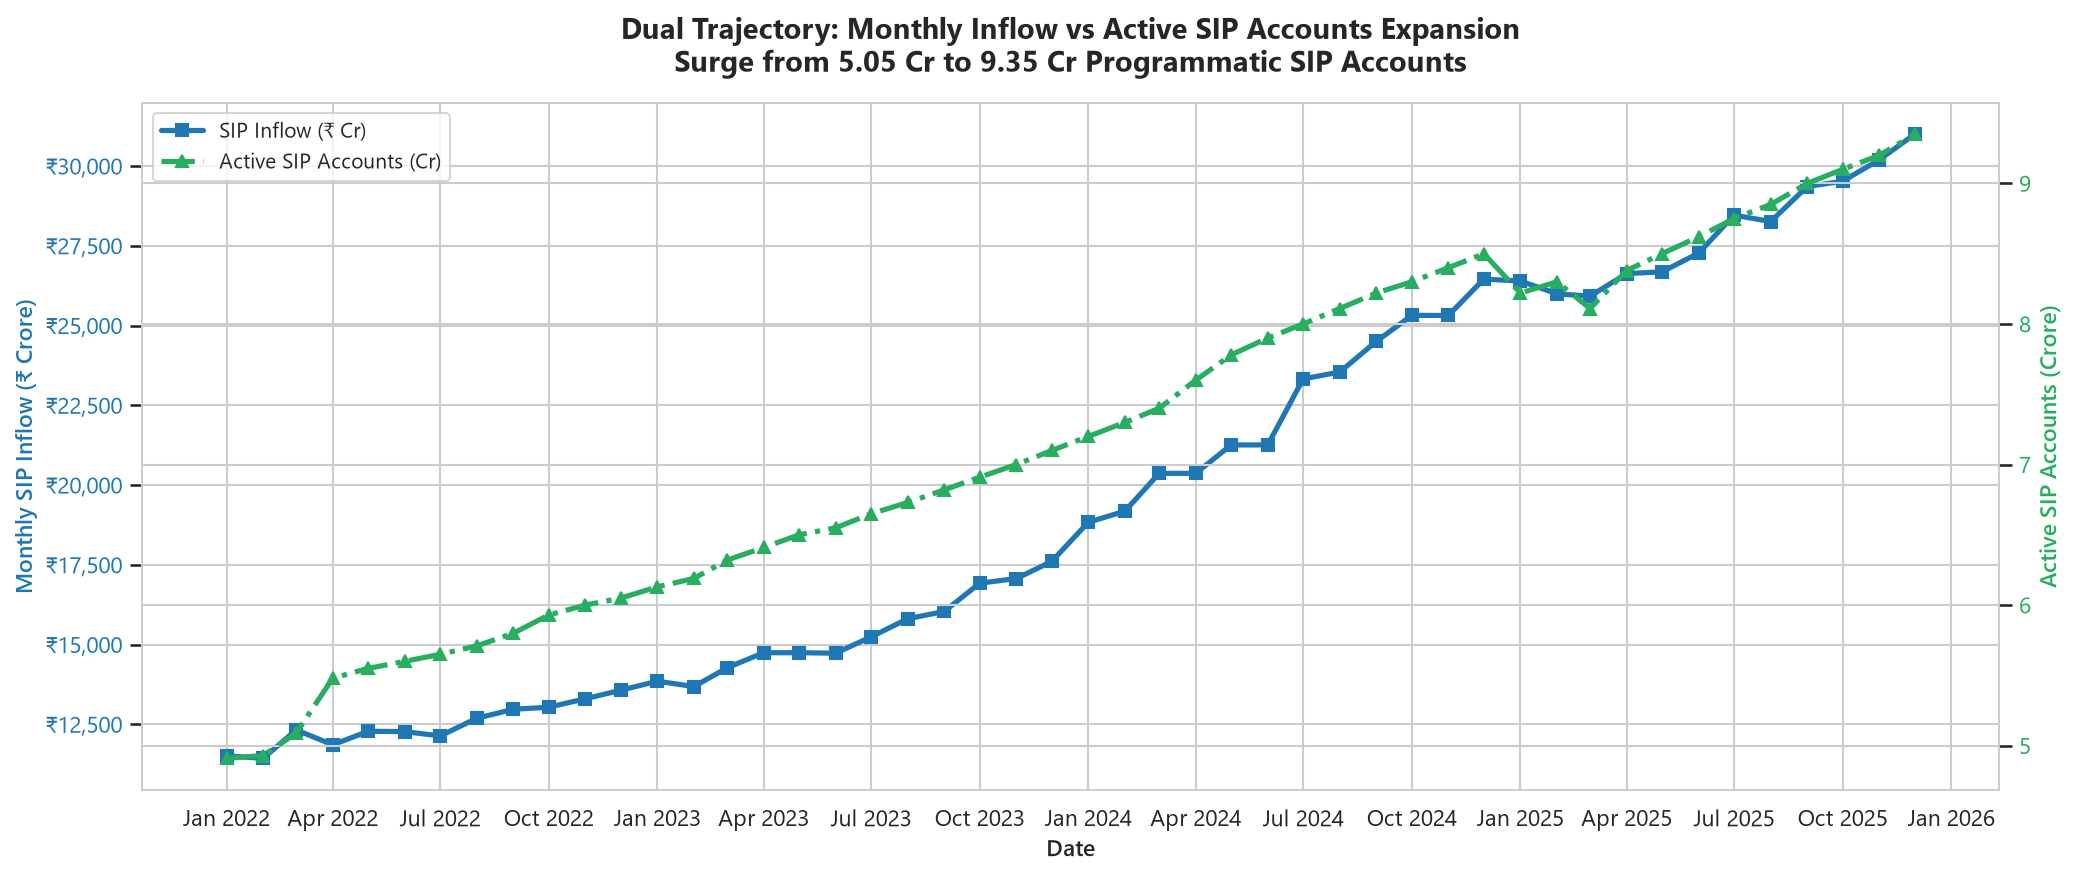

Exported: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics\reports\eda_charts\chart_06_sip_accounts_vs_inflow.png


In [7]:
# Static Export: Chart 5 Monthly SIP Inflows (Matplotlib High-Res PNG)
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(df_sip['date'], df_sip['sip_inflow_crore'], color='#1f77b4', linewidth=2.8, marker='o', markersize=5, label='Monthly SIP Inflow (₹ Cr)')
ax.fill_between(df_sip['date'], df_sip['sip_inflow_crore'], color='#1f77b4', alpha=0.15)
ax.plot(df_sip['date'], df_sip['sip_12m_ma'], color='#e67e22', linestyle='--', linewidth=2, label='6-Month Moving Average')

# Annotate ₹31,002 Cr ATH
ax.annotate(
    f"All-Time High: ₹31,002 Cr\n(Dec 2025 | YoY: +17.2%)",
    xy=(pd.to_datetime("2025-12-01"), 31002),
    xytext=(pd.to_datetime("2024-06-01"), 30000),
    arrowprops=dict(facecolor='#d62728', edgecolor='#d62728', shrink=0.05, width=2, headwidth=8),
    fontsize=11,
    fontweight='bold',
    color='#b03a2e',
    bbox=dict(boxstyle="round,pad=0.4", fc="#fadbd8", ec="#b03a2e", lw=1.2)
)

ax.set_title("Monthly SIP Inflow Trajectory (Jan 2022 – Dec 2025)\nMarking the ₹31,002 Crore All-Time High in December 2025", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Date", fontsize=11, fontweight='semibold')
ax.set_ylabel("Monthly SIP Inflow (₹ Crore)", fontsize=11, fontweight='semibold')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('₹{x:,.0f}'))
ax.legend(loc='upper left', frameon=True, fontsize=10)
plt.xticks(rotation=30)
plt.tight_layout()

chart5_path = CHARTS_DIR / "chart_05_monthly_sip_inflows.png"
plt.savefig(chart5_path, dpi=300)
plt.show()
print(f"Exported: {chart5_path}")

# --- Chart 6: SIP Inflows vs Active SIP Accounts & SIP AUM (Dual Axis) ---
fig, ax1 = plt.subplots(figsize=(14, 6))

color = '#1f77b4'
ax1.set_xlabel('Date', fontsize=11, fontweight='semibold')
ax1.set_ylabel('Monthly SIP Inflow (₹ Crore)', color=color, fontsize=11, fontweight='semibold')
line1 = ax1.plot(df_sip['date'], df_sip['sip_inflow_crore'], color=color, linewidth=2.5, marker='s', label='SIP Inflow (₹ Cr)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter('₹{x:,.0f}'))

ax2 = ax1.twinx()
color = '#27ae60'
ax2.set_ylabel('Active SIP Accounts (Crore)', color=color, fontsize=11, fontweight='semibold')
line2 = ax2.plot(df_sip['date'], df_sip['active_sip_accounts_crore'], color=color, linewidth=2.5, linestyle='-.', marker='^', label='Active SIP Accounts (Cr)')
ax2.tick_params(axis='y', labelcolor=color)

# Combined legend
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', frameon=True, fontsize=10)

ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.title("Dual Trajectory: Monthly Inflow vs Active SIP Accounts Expansion\nSurge from 5.05 Cr to 9.35 Cr Programmatic SIP Accounts", fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=30)
plt.tight_layout()

chart6_path = CHARTS_DIR / "chart_06_sip_accounts_vs_inflow.png"
plt.savefig(chart6_path, dpi=300)
plt.show()
print(f"Exported: {chart6_path}")


---
## 4. 🌡️ Category Net Inflows Heatmap (Seaborn)

### Cyclical vs Structural Demand:
Analyzing category net inflows over a rolling 12-month window reveals distinct investor preferences:
- **Flexi Cap, Small Cap, and Mid Cap** witnessed persistent high net inflows (>₹3,000–₹5,000 Cr/month), reflecting aggressive wealth accumulation appetites.
- **Debt and Liquid Funds** experienced volatile cyclical lumpy flows, registering deep red negative net inflows during quarter-end advance tax payments and corporate liquidity management windows.


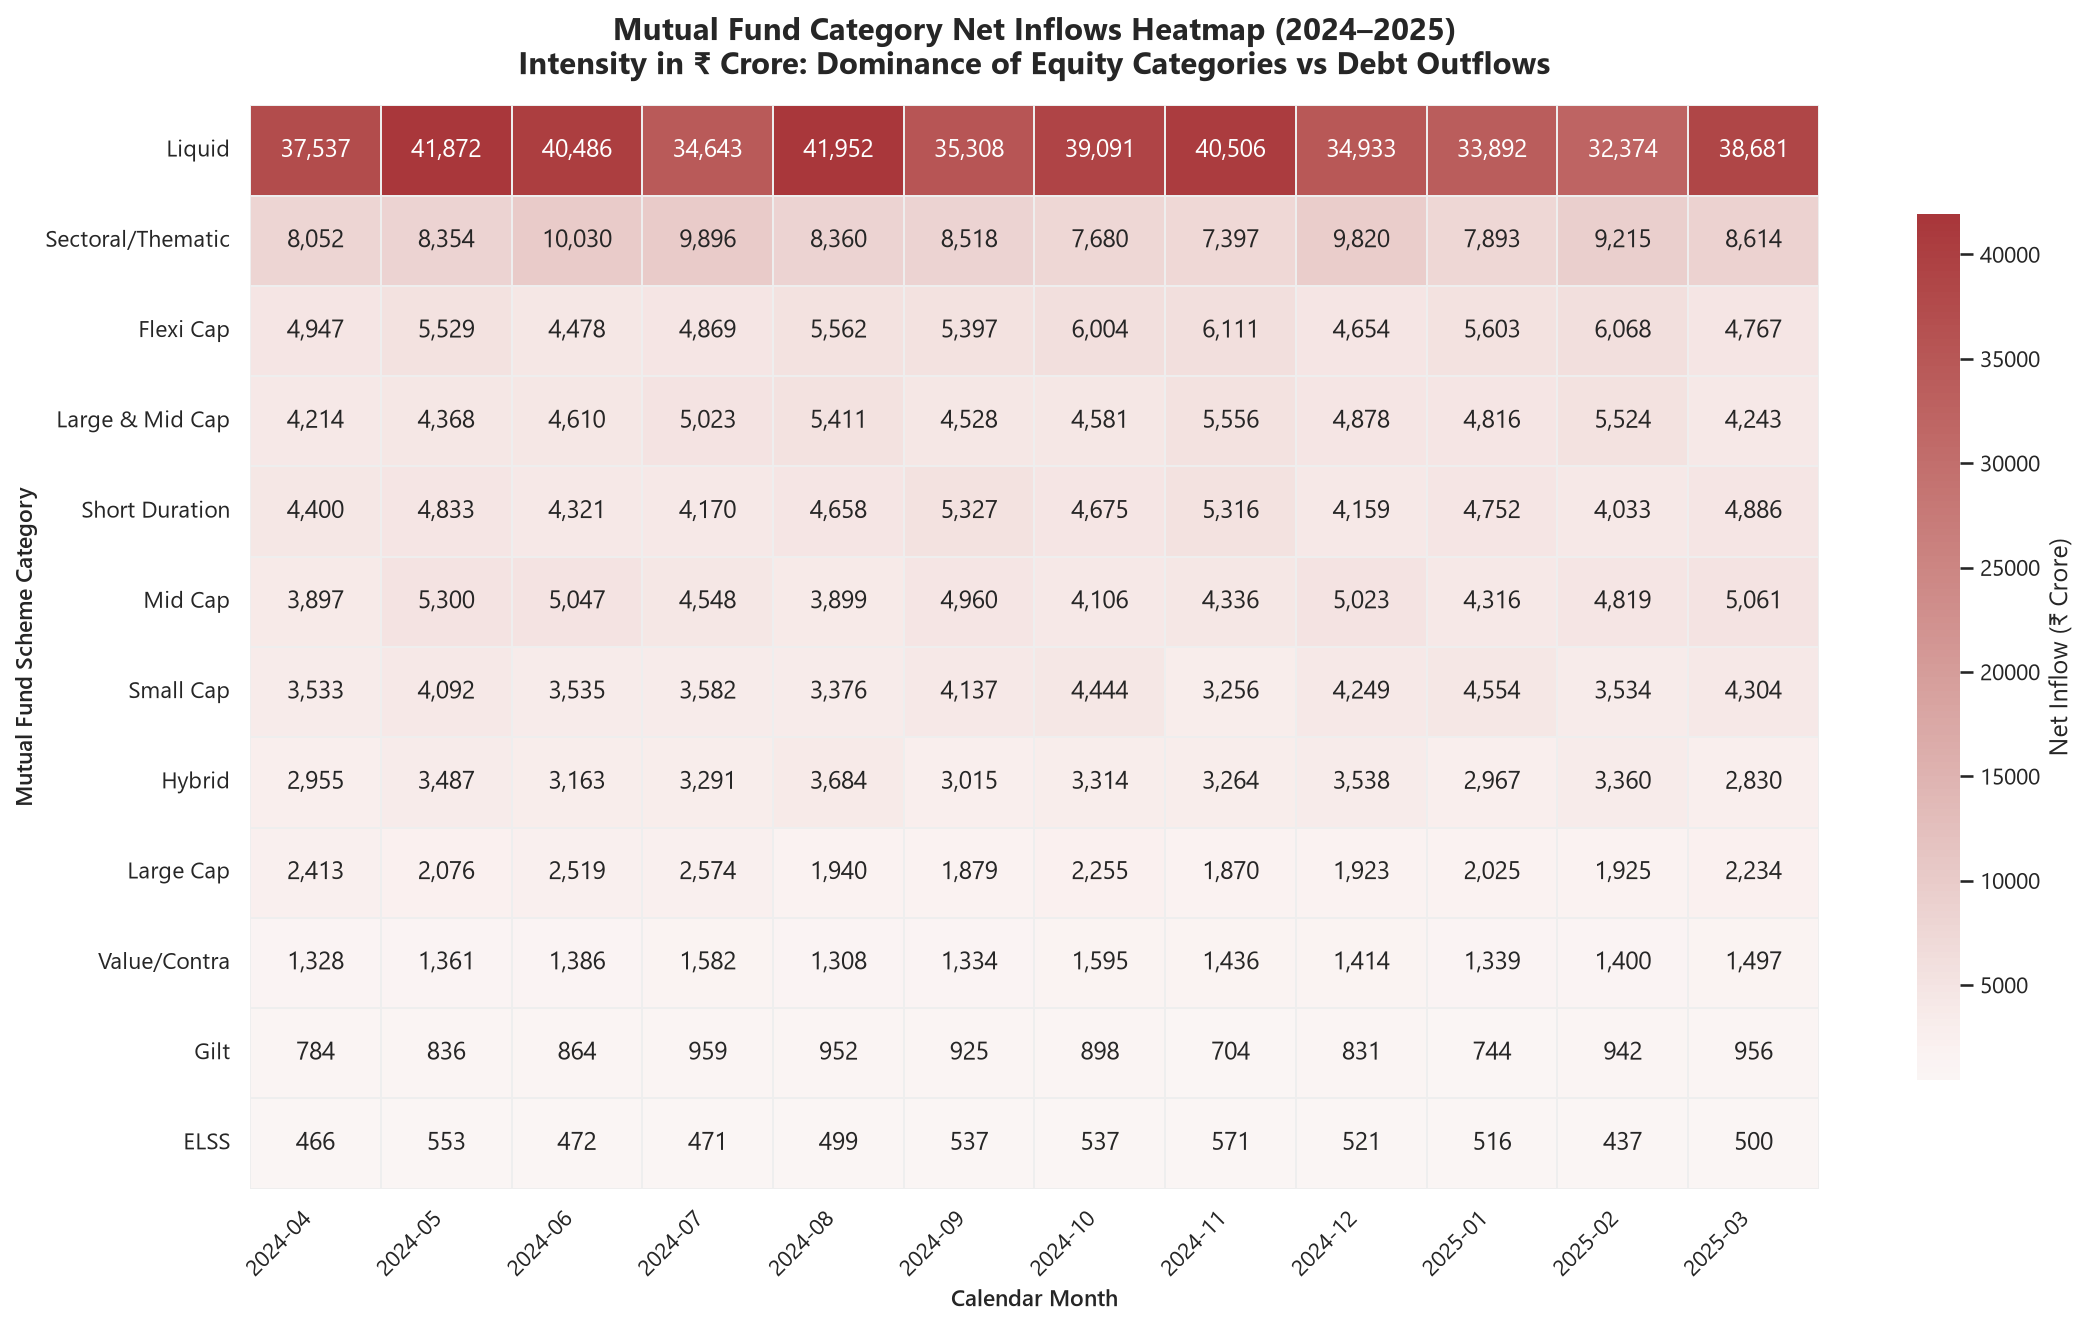

Exported: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics\reports\eda_charts\chart_07_category_inflow_heatmap.png


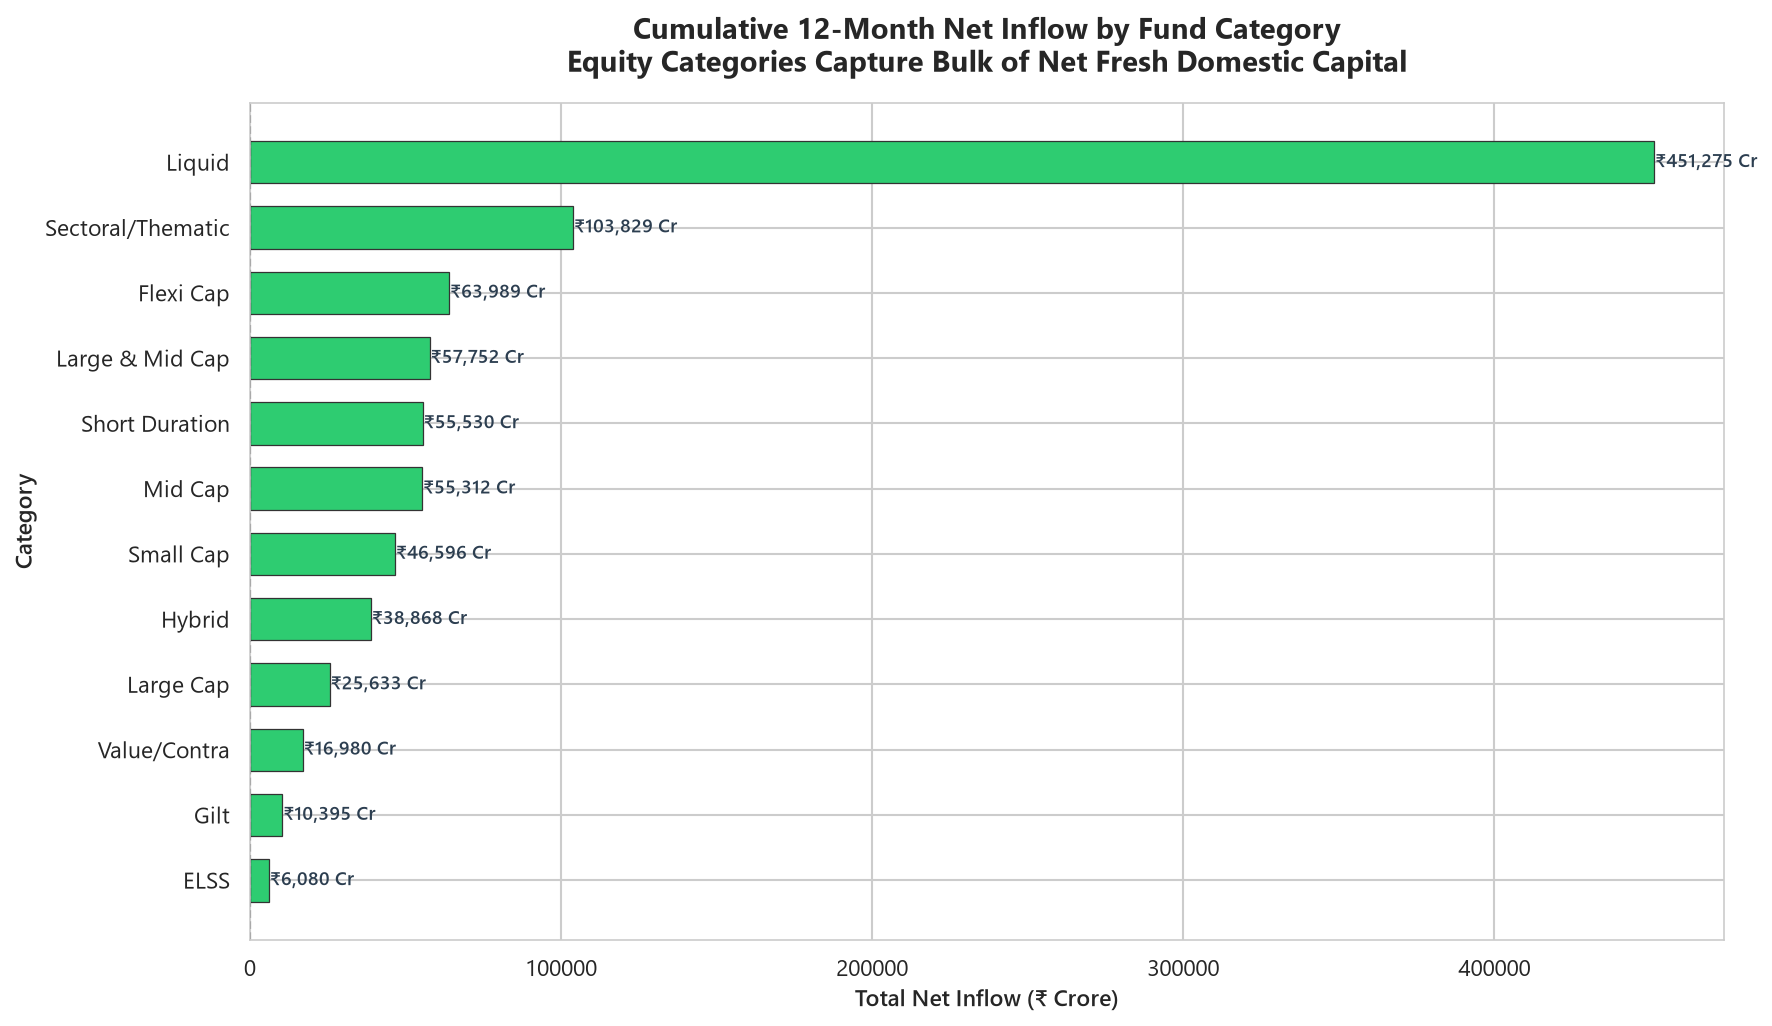

Exported: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics\reports\eda_charts\chart_08_cumulative_category_inflows.png


In [8]:
# Chart 7: Category Inflow Heatmap using Seaborn
# Pivot: Rows = Category, Columns = Month, Values = Net Inflow
cat_pivot = df_cat_inflow.pivot(index='category', columns='month', values='net_inflow_crore')

# Sort categories by total cumulative net inflow
cat_order = cat_pivot.sum(axis=1).sort_values(ascending=False).index
cat_pivot = cat_pivot.loc[cat_order]

fig, ax = plt.subplots(figsize=(15, 9))

# Heatmap with diverging colormap centered at 0
sns.heatmap(
    cat_pivot,
    cmap='vlag',
    center=0,
    annot=True,
    fmt=',.0f',
    linewidths=0.8,
    linecolor='#eeeeee',
    cbar_kws={'label': 'Net Inflow (₹ Crore)', 'shrink': 0.8},
    ax=ax
)

ax.set_title("Mutual Fund Category Net Inflows Heatmap (2024–2025)\nIntensity in ₹ Crore: Dominance of Equity Categories vs Debt Outflows", fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel("Calendar Month", fontsize=11, fontweight='semibold')
ax.set_ylabel("Mutual Fund Scheme Category", fontsize=11, fontweight='semibold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

chart7_path = CHARTS_DIR / "chart_07_category_inflow_heatmap.png"
plt.savefig(chart7_path, dpi=300)
plt.show()
print(f"Exported: {chart7_path}")

# --- Chart 8: Cumulative 12-Month Net Inflow by Category (Ranked Horizontal Bar) ---
cum_cat = df_cat_inflow.groupby('category')['net_inflow_crore'].sum().sort_values()

fig, ax = plt.subplots(figsize=(12, 7))
bar_colors = ['#e74c3c' if val < 0 else '#2ecc71' for val in cum_cat.values]

bars = ax.barh(cum_cat.index, cum_cat.values, color=bar_colors, edgecolor='#333333', linewidth=0.6, height=0.65)

# Value labels on bars
for bar in bars:
    w = bar.get_width()
    offset = 400 if w >= 0 else -1800
    ax.annotate(f"₹{w:,.0f} Cr", (w + offset, bar.get_y() + bar.get_height() / 2.),
                va='center', fontsize=9, fontweight='semibold', color='#2c3e50')

ax.axvline(0, color='black', linewidth=1, linestyle='--')
ax.set_title("Cumulative 12-Month Net Inflow by Fund Category\nEquity Categories Capture Bulk of Net Fresh Domestic Capital", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Total Net Inflow (₹ Crore)", fontsize=11, fontweight='semibold')
ax.set_ylabel("Category", fontsize=11, fontweight='semibold')
plt.tight_layout()

chart8_path = CHARTS_DIR / "chart_08_cumulative_category_inflows.png"
plt.savefig(chart8_path, dpi=300)
plt.show()
print(f"Exported: {chart8_path}")


---
## 5. 👥 Investor Demographics & Behavioral Profiling

### Demographic Segmentation:
Examining the micro-data of 32,778 retail investor transactions yields crucial behavioral insights:
- **Age Distribution**: Millennials (**26–35 age group**) form the largest cohort (**41.1%**), followed by Generation X (**36–45 at 24.9%**). Young investors under 35 constitute over **56%** of all transaction activity.
- **SIP Ticket Size**: While younger investors (18–25) participate actively, the median SIP ticket size remains remarkably consistent across age groups (**₹5,000–₹5,400**), reflecting structural minimum SIP commitments.
- **Gender Dynamics**: Male investors account for **66.5%** of transactions and female investors represent **33.5%**, with female participation expanding rapidly through digital KYC platforms.


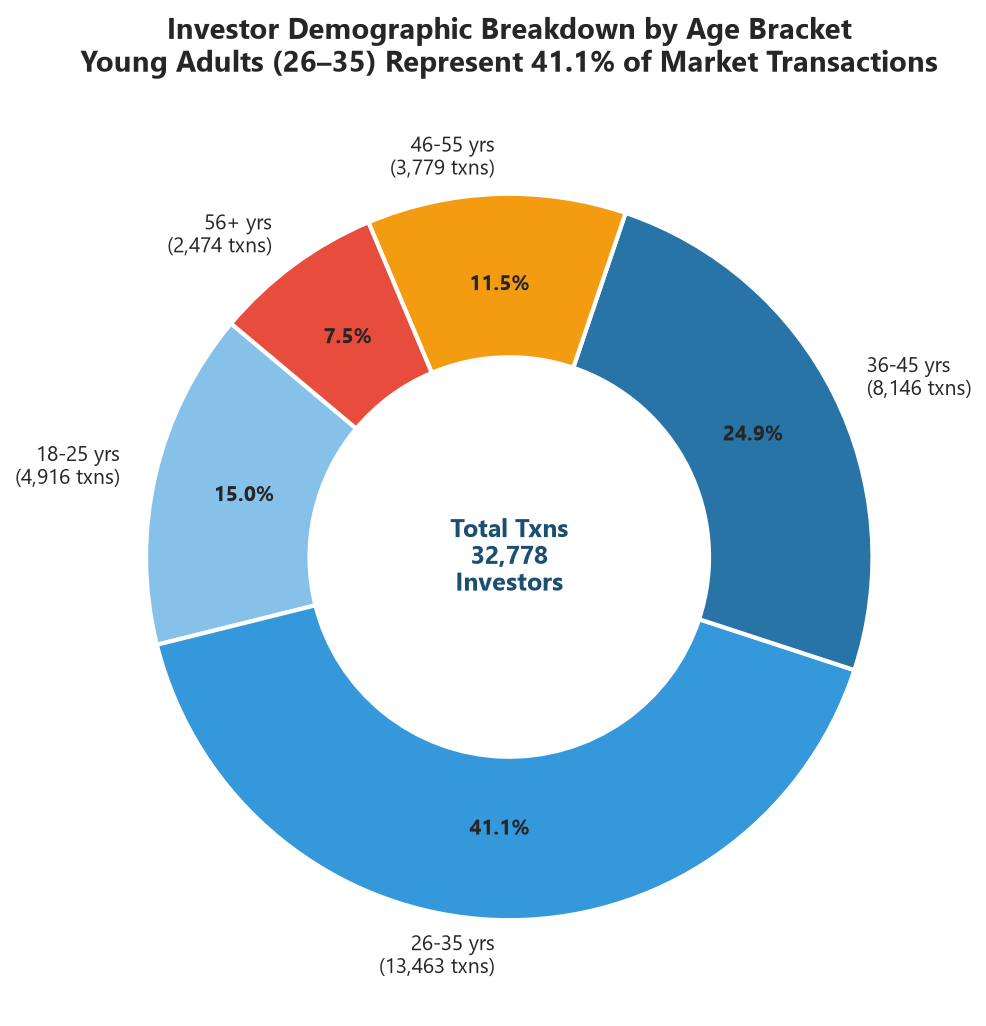

Exported: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics\reports\eda_charts\chart_09_investor_age_distribution.png


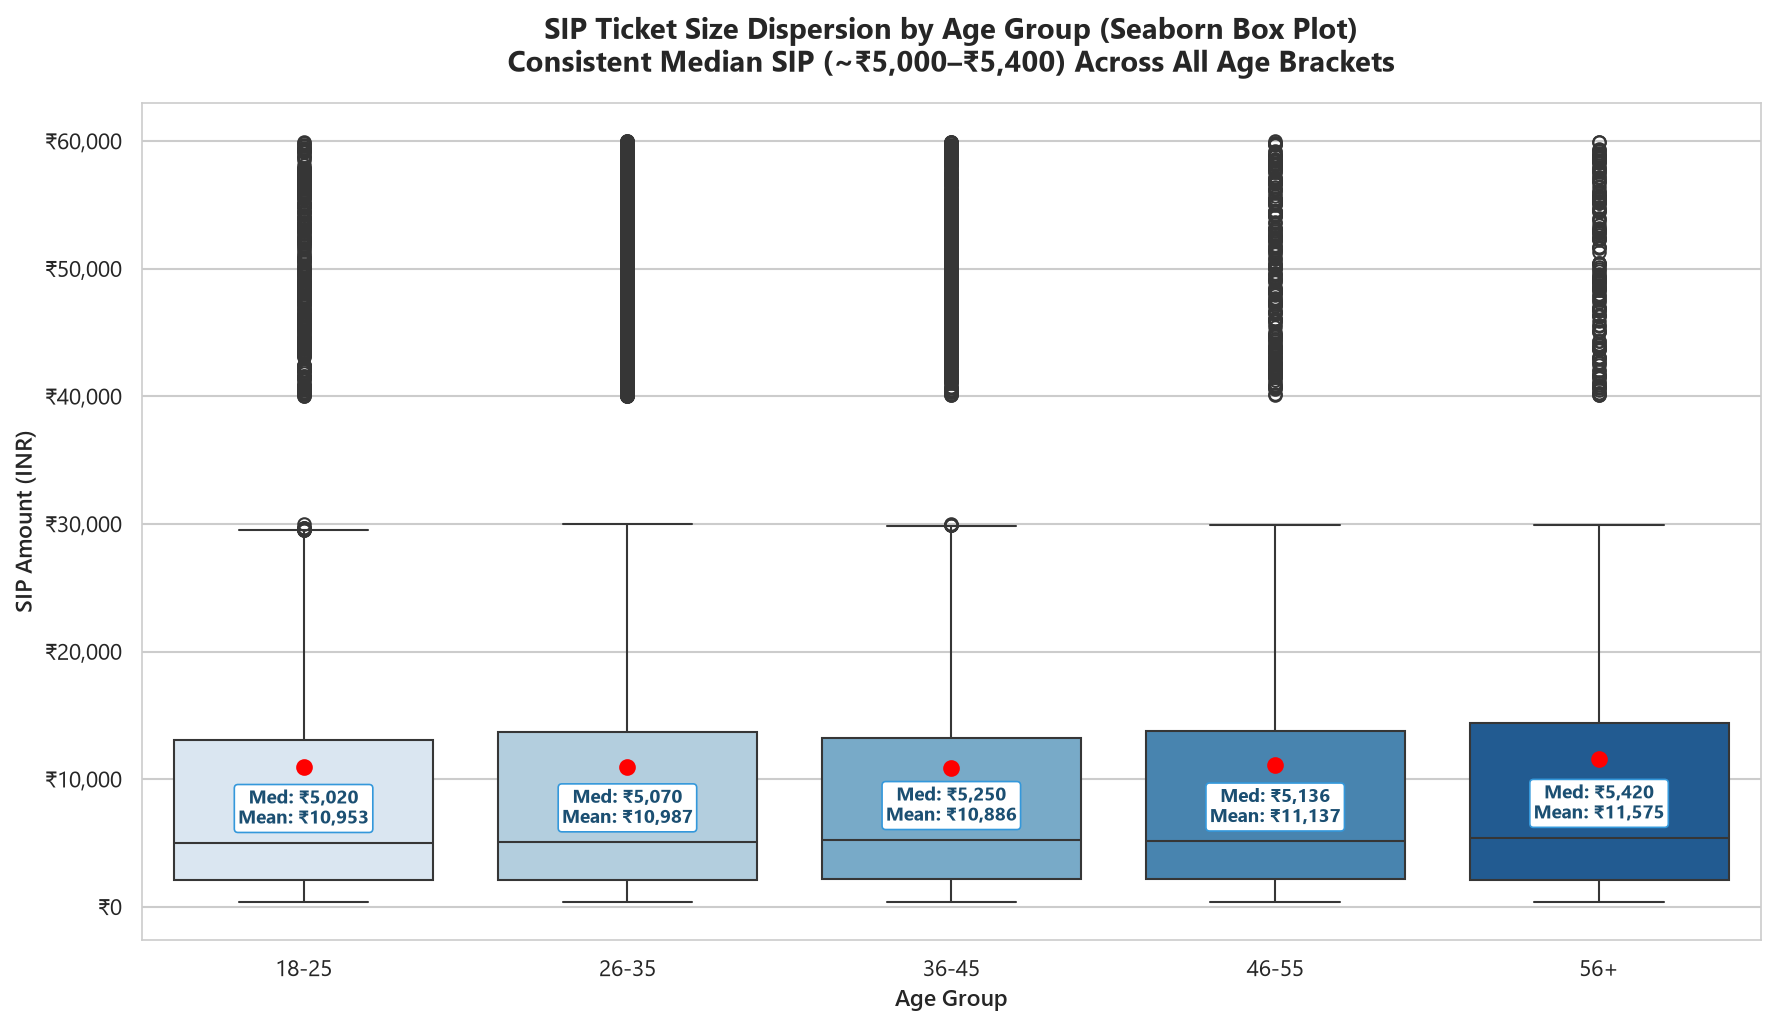

Exported: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics\reports\eda_charts\chart_10_sip_amount_by_age_boxplot.png


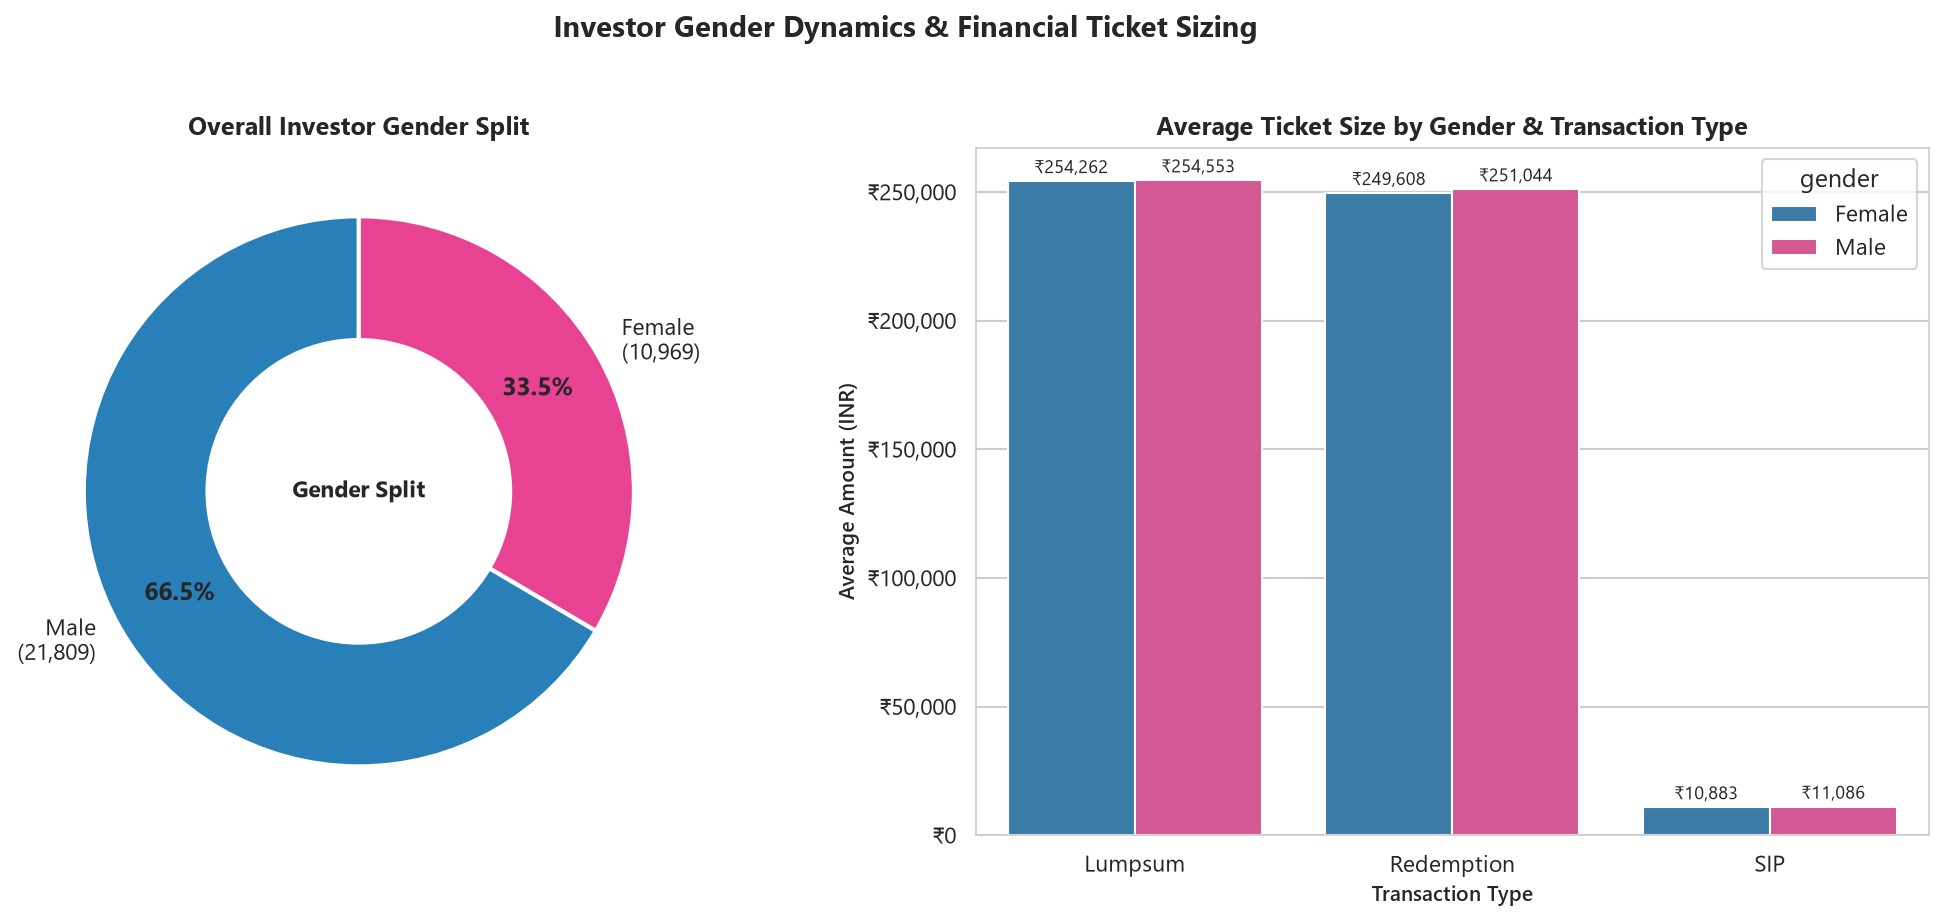

Exported: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics\reports\eda_charts\chart_11_investor_gender_split.png


In [9]:
# Chart 9: Investor Age Group Distribution (Pie / Donut Chart)
age_counts = df_txn['age_group'].value_counts()[['18-25', '26-35', '36-45', '46-55', '56+']]

fig, ax = plt.subplots(figsize=(9, 7))
colors_age = ['#85c1e9', '#3498db', '#2874a6', '#f39c12', '#e74c3c']

wedges, texts, autotexts = ax.pie(
    age_counts,
    labels=[f"{k} yrs\n({v:,} txns)" for k, v in age_counts.items()],
    autopct='%1.1f%%',
    pctdistance=0.75,
    startangle=140,
    colors=colors_age,
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2),
    textprops={'fontsize': 10}
)

for autotext in autotexts:
    autotext.set_fontweight('bold')
    autotext.set_fontsize(10)

ax.text(0, 0, f"Total Txns\n{len(df_txn):,}\nInvestors", ha='center', va='center', fontsize=12, fontweight='bold', color='#1b4f72')
ax.set_title("Investor Demographic Breakdown by Age Bracket\nYoung Adults (26–35) Represent 41.1% of Market Transactions", fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()

chart9_path = CHARTS_DIR / "chart_09_investor_age_distribution.png"
plt.savefig(chart9_path, dpi=300)
plt.show()
print(f"Exported: {chart9_path}")

# --- Chart 10: SIP Amount Distribution by Age Group (Seaborn Box Plot) ---
df_sip_txns = df_txn[df_txn['transaction_type'] == 'SIP']
age_order = ['18-25', '26-35', '36-45', '46-55', '56+']

fig, ax = plt.subplots(figsize=(12, 7))

sns.boxplot(
    data=df_sip_txns,
    x='age_group',
    y='amount_inr',
    order=age_order,
    palette='Blues',
    showmeans=True,
    meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"red", "markersize":"7"},
    ax=ax
)

# Overlay Median Labels
medians = df_sip_txns.groupby('age_group')['amount_inr'].median()[age_order]
means = df_sip_txns.groupby('age_group')['amount_inr'].mean()[age_order]

for idx, age in enumerate(age_order):
    med = medians[age]
    mean_val = means[age]
    ax.text(idx, med + 1500, f"Med: ₹{med:,.0f}\nMean: ₹{mean_val:,.0f}", ha='center', fontsize=9, fontweight='bold', color='#1b4f72',
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="#3498db", lw=0.8))

ax.set_title("SIP Ticket Size Dispersion by Age Group (Seaborn Box Plot)\nConsistent Median SIP (~₹5,000–₹5,400) Across All Age Brackets", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Age Group", fontsize=11, fontweight='semibold')
ax.set_ylabel("SIP Amount (INR)", fontsize=11, fontweight='semibold')
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('₹{x:,.0f}'))
plt.tight_layout()

chart10_path = CHARTS_DIR / "chart_10_sip_amount_by_age_boxplot.png"
plt.savefig(chart10_path, dpi=300)
plt.show()
print(f"Exported: {chart10_path}")

# --- Chart 11: Gender Split & Transaction Profile ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Gender Distribution Donut
gender_counts = df_txn['gender'].value_counts()
colors_gender = ['#2980b9', '#e84393']
wedges, texts, autotexts = ax1.pie(
    gender_counts,
    labels=[f"{k}\n({v:,})" for k, v in gender_counts.items()],
    autopct='%1.1f%%',
    startangle=90,
    colors=colors_gender,
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2),
    pctdistance=0.75
)
for at in autotexts:
    at.set_fontweight('bold')
ax1.text(0, 0, "Gender Split", ha='center', va='center', fontsize=11, fontweight='bold')
ax1.set_title("Overall Investor Gender Split", fontsize=12, fontweight='bold')

# Subplot 2: Average Ticket Size by Gender and Transaction Type
df_grouped_gender = df_txn.groupby(['transaction_type', 'gender'])['amount_inr'].mean().reset_index()
sns.barplot(
    data=df_grouped_gender,
    x='transaction_type',
    y='amount_inr',
    hue='gender',
    palette=['#2980b9', '#e84393'],
    ax=ax2
)
for p in ax2.patches:
    h = p.get_height()
    if h > 0:
        ax2.annotate(f"₹{h:,.0f}", (p.get_x() + p.get_width() / 2., h),
                     ha='center', va='bottom', fontsize=8.5, xytext=(0, 2), textcoords='offset points')

ax2.set_title("Average Ticket Size by Gender & Transaction Type", fontsize=12, fontweight='bold')
ax2.set_xlabel("Transaction Type", fontsize=10, fontweight='semibold')
ax2.set_ylabel("Average Amount (INR)", fontsize=10, fontweight='semibold')
ax2.yaxis.set_major_formatter(ticker.StrMethodFormatter('₹{x:,.0f}'))

plt.suptitle("Investor Gender Dynamics & Financial Ticket Sizing", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()

chart11_path = CHARTS_DIR / "chart_11_investor_gender_split.png"
plt.savefig(chart11_path, dpi=300)
plt.show()
print(f"Exported: {chart11_path}")


---
## 6. 🌍 Geographic Distribution: State-wise SIP Flows & T30 vs B30

### Regional Financialization:
Mutual fund capital mobilization is penetrating deep into India's geographic footprint:
- **Top States**: Madhya Pradesh, Punjab, Telangana, Tamil Nadu, and Gujarat lead in cumulative SIP volume, showcasing balanced geographical dispersion across Northern, Western, and Southern economic hubs.
- **T30 vs B30 Penetration**: Beyond-30 (B30) cities represent **33.7%** of total transaction volumes, underscoring substantial financial deepening into Tier-2, Tier-3, and rural centers enabled by digital payment infrastructure (UPI, Net Banking).


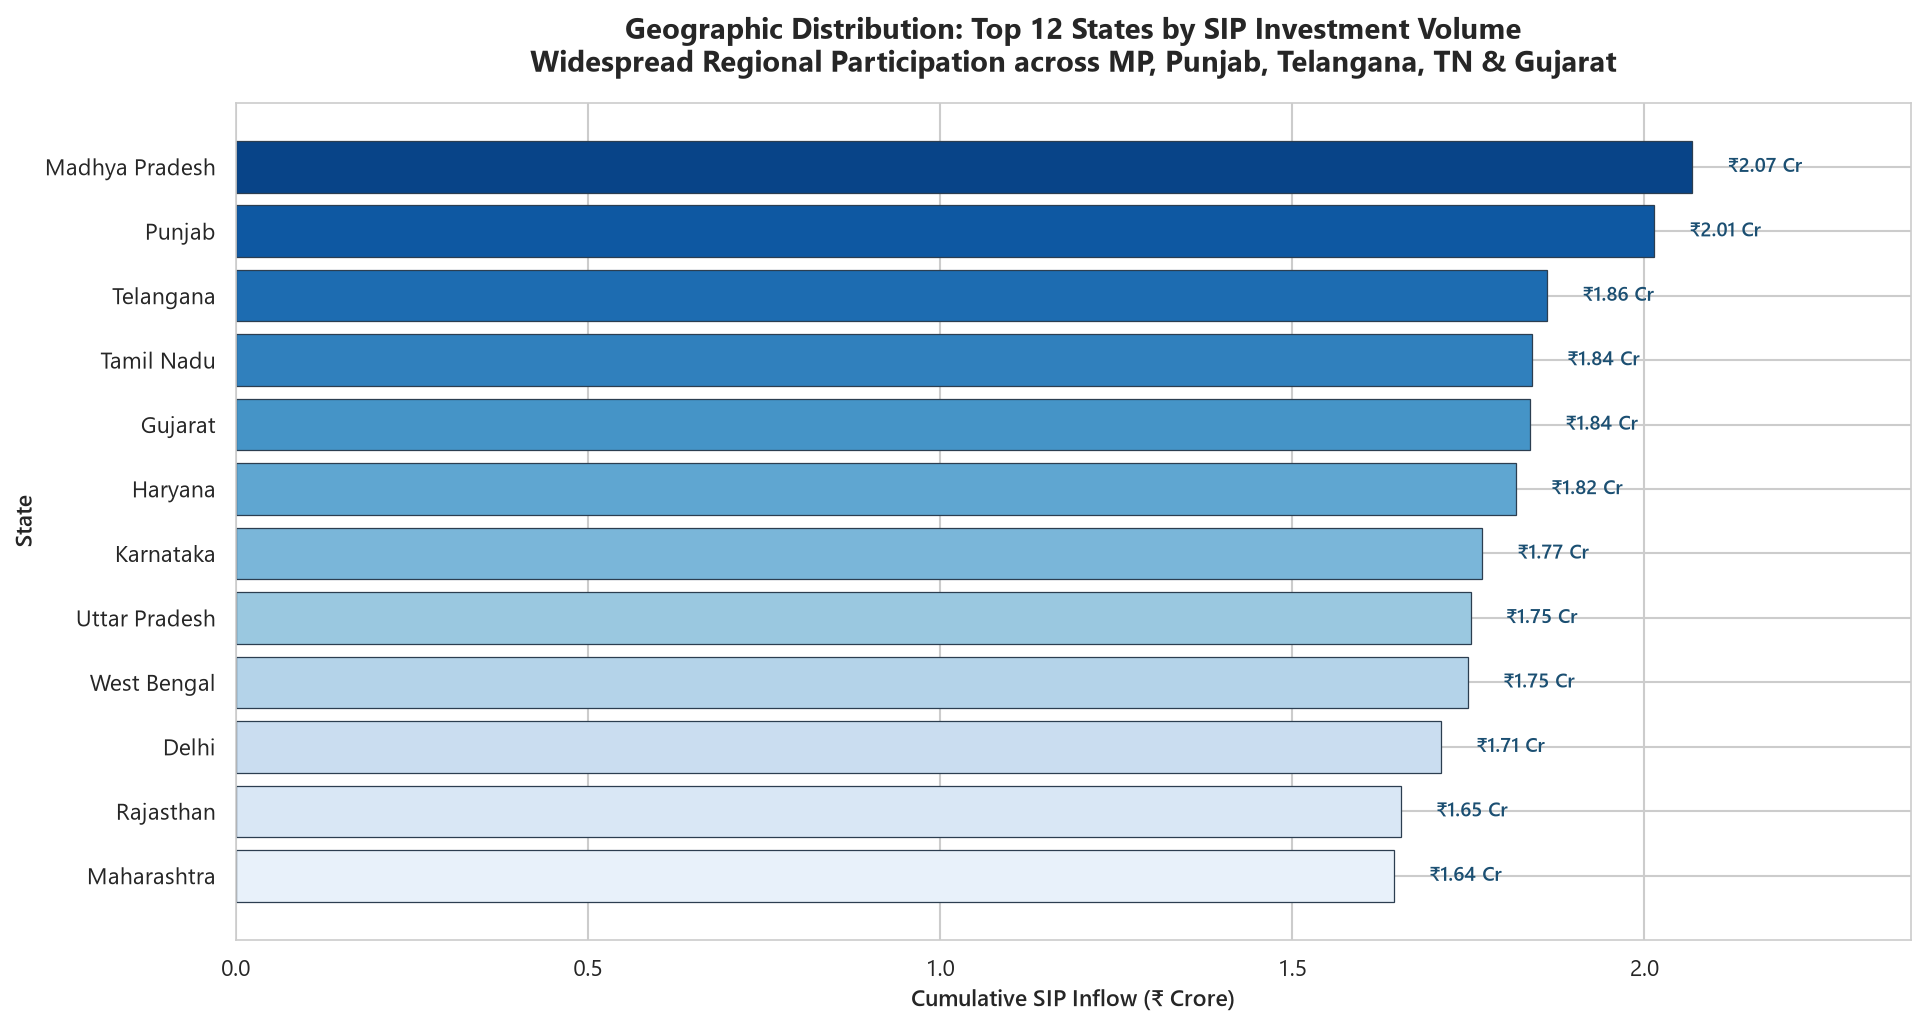

Exported: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics\reports\eda_charts\chart_12_sip_inflow_by_state.png


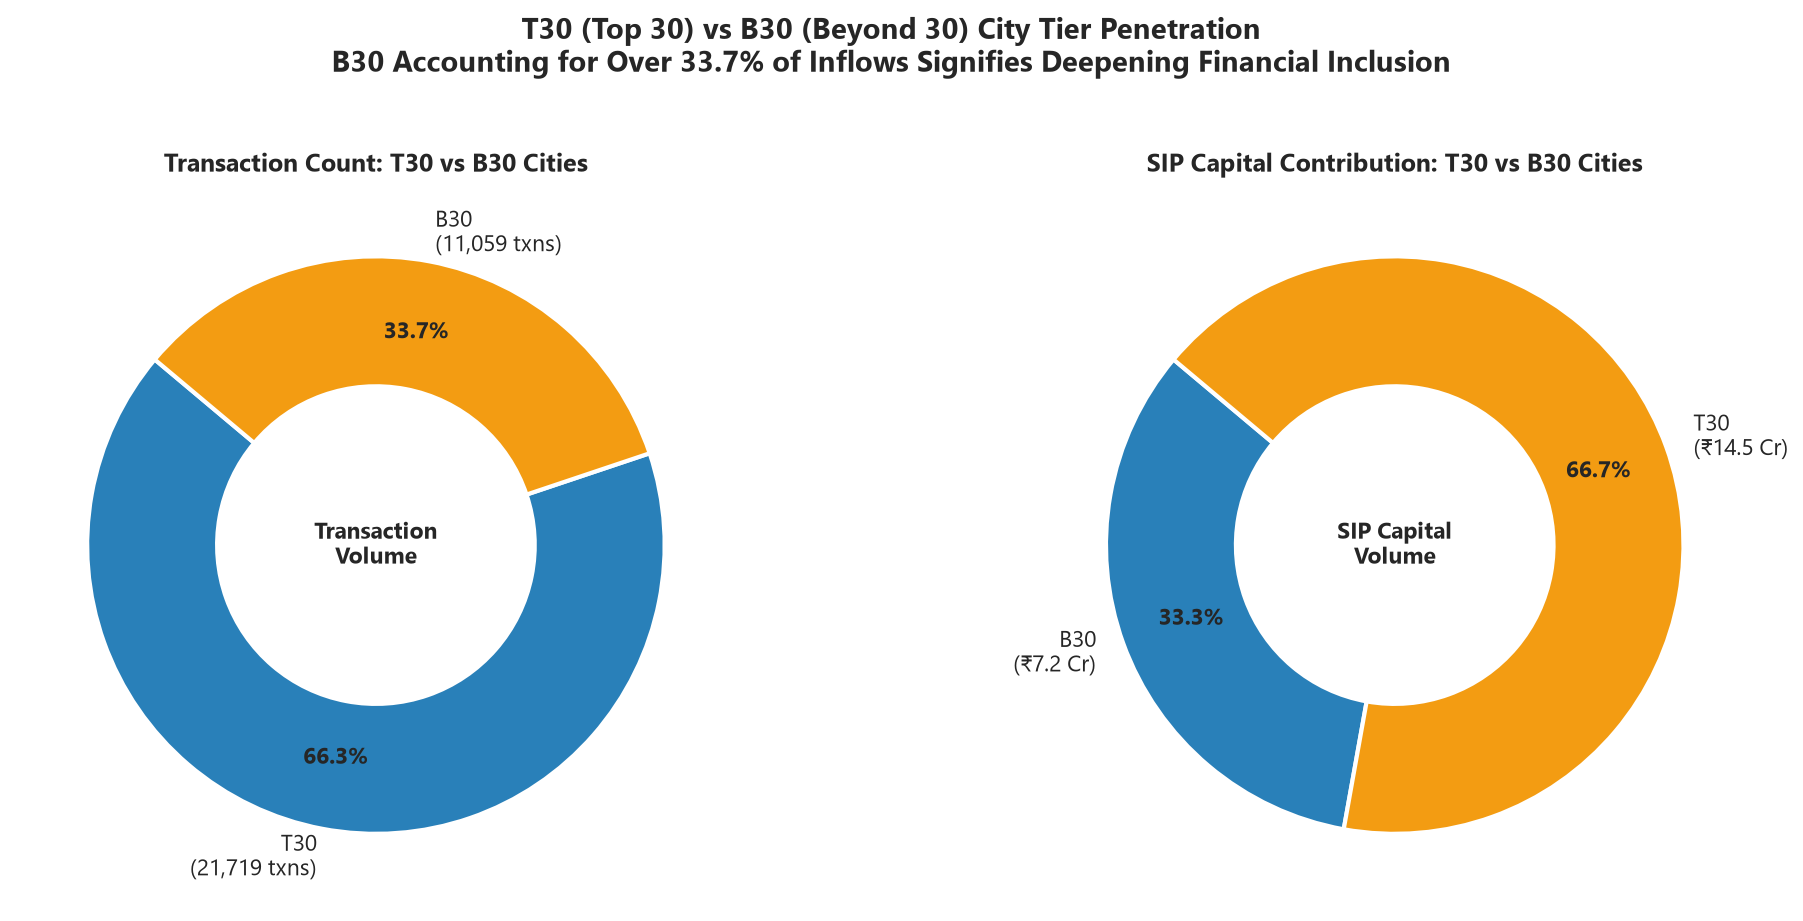

Exported: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics\reports\eda_charts\chart_13_city_tier_t30_b30.png


In [10]:
# Chart 12: Horizontal Bar Chart of SIP Amount by State using Seaborn
state_sip = df_sip_txns.groupby('state')['amount_inr'].sum().sort_values(ascending=False).head(12)

fig, ax = plt.subplots(figsize=(13, 7))
palette_state = sns.color_palette("Blues_r", len(state_sip))

bars = ax.barh(state_sip.index[::-1], (state_sip.values / 1e7)[::-1], color=palette_state[::-1], edgecolor='#2c3e50', linewidth=0.6)

# Annotate values in ₹ Crore
for bar in bars:
    w = bar.get_width()
    ax.annotate(f"₹{w:.2f} Cr", (w + 0.05, bar.get_y() + bar.get_height() / 2.),
                va='center', fontsize=9.5, fontweight='semibold', color='#1b4f72')

ax.set_title("Geographic Distribution: Top 12 States by SIP Investment Volume\nWidespread Regional Participation across MP, Punjab, Telangana, TN & Gujarat", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Cumulative SIP Inflow (₹ Crore)", fontsize=11, fontweight='semibold')
ax.set_ylabel("State", fontsize=11, fontweight='semibold')
ax.set_xlim(0, max(state_sip.values / 1e7) * 1.15)
plt.tight_layout()

chart12_path = CHARTS_DIR / "chart_12_sip_inflow_by_state.png"
plt.savefig(chart12_path, dpi=300)
plt.show()
print(f"Exported: {chart12_path}")

# --- Chart 13: T30 vs B30 City Tier Distribution Donut Chart ---
tier_counts = df_txn['city_tier'].value_counts()
tier_sip_sum = df_sip_txns.groupby('city_tier')['amount_inr'].sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Donut 1: Transaction Volume Split
colors_tier = ['#2980b9', '#f39c12']
wedges, texts, autotexts = ax1.pie(
    tier_counts,
    labels=[f"{k}\n({v:,} txns)" for k, v in tier_counts.items()],
    autopct='%1.1f%%',
    startangle=140,
    colors=colors_tier,
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2),
    pctdistance=0.75
)
for at in autotexts:
    at.set_fontweight('bold')
    at.set_fontsize(11)
ax1.text(0, 0, "Transaction\nVolume", ha='center', va='center', fontsize=11, fontweight='bold')
ax1.set_title("Transaction Count: T30 vs B30 Cities", fontsize=12, fontweight='bold')

# Donut 2: SIP Capital Split
wedges, texts, autotexts = ax2.pie(
    tier_sip_sum,
    labels=[f"{k}\n(₹{v/1e7:.1f} Cr)" for k, v in tier_sip_sum.items()],
    autopct='%1.1f%%',
    startangle=140,
    colors=colors_tier,
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2),
    pctdistance=0.75
)
for at in autotexts:
    at.set_fontweight('bold')
    at.set_fontsize(11)
ax2.text(0, 0, "SIP Capital\nVolume", ha='center', va='center', fontsize=11, fontweight='bold')
ax2.set_title("SIP Capital Contribution: T30 vs B30 Cities", fontsize=12, fontweight='bold')

plt.suptitle("T30 (Top 30) vs B30 (Beyond 30) City Tier Penetration\nB30 Accounting for Over 33.7% of Inflows Signifies Deepening Financial Inclusion", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()

chart13_path = CHARTS_DIR / "chart_13_city_tier_t30_b30.png"
plt.savefig(chart13_path, dpi=300)
plt.show()
print(f"Exported: {chart13_path}")


---
## 7. 📈 Industry Folio Count Expansion & Key Milestones

### The Retail Investor Influx:
Mutual fund folio count represents the structural foundation of retail equity participation.
- Total industry folios doubled (+97.0%) from **13.26 Crore in January 2022** to **26.12 Crore in December 2025**.
- Key milestones crossed:
  * **15.0 Crore Folios**: Reached in May 2023
  * **17.5 Crore Folios**: Reached in February 2024
  * **20.0 Crore Folios**: Reached in October 2024
  * **25.0 Crore Folios**: Reached in July 2025
  * **26.12 Crore Folios**: December 2025 Closing Record
- Equity schemes drove over **88%** of net folio additions, illustrating unprecedented equity market adoption.


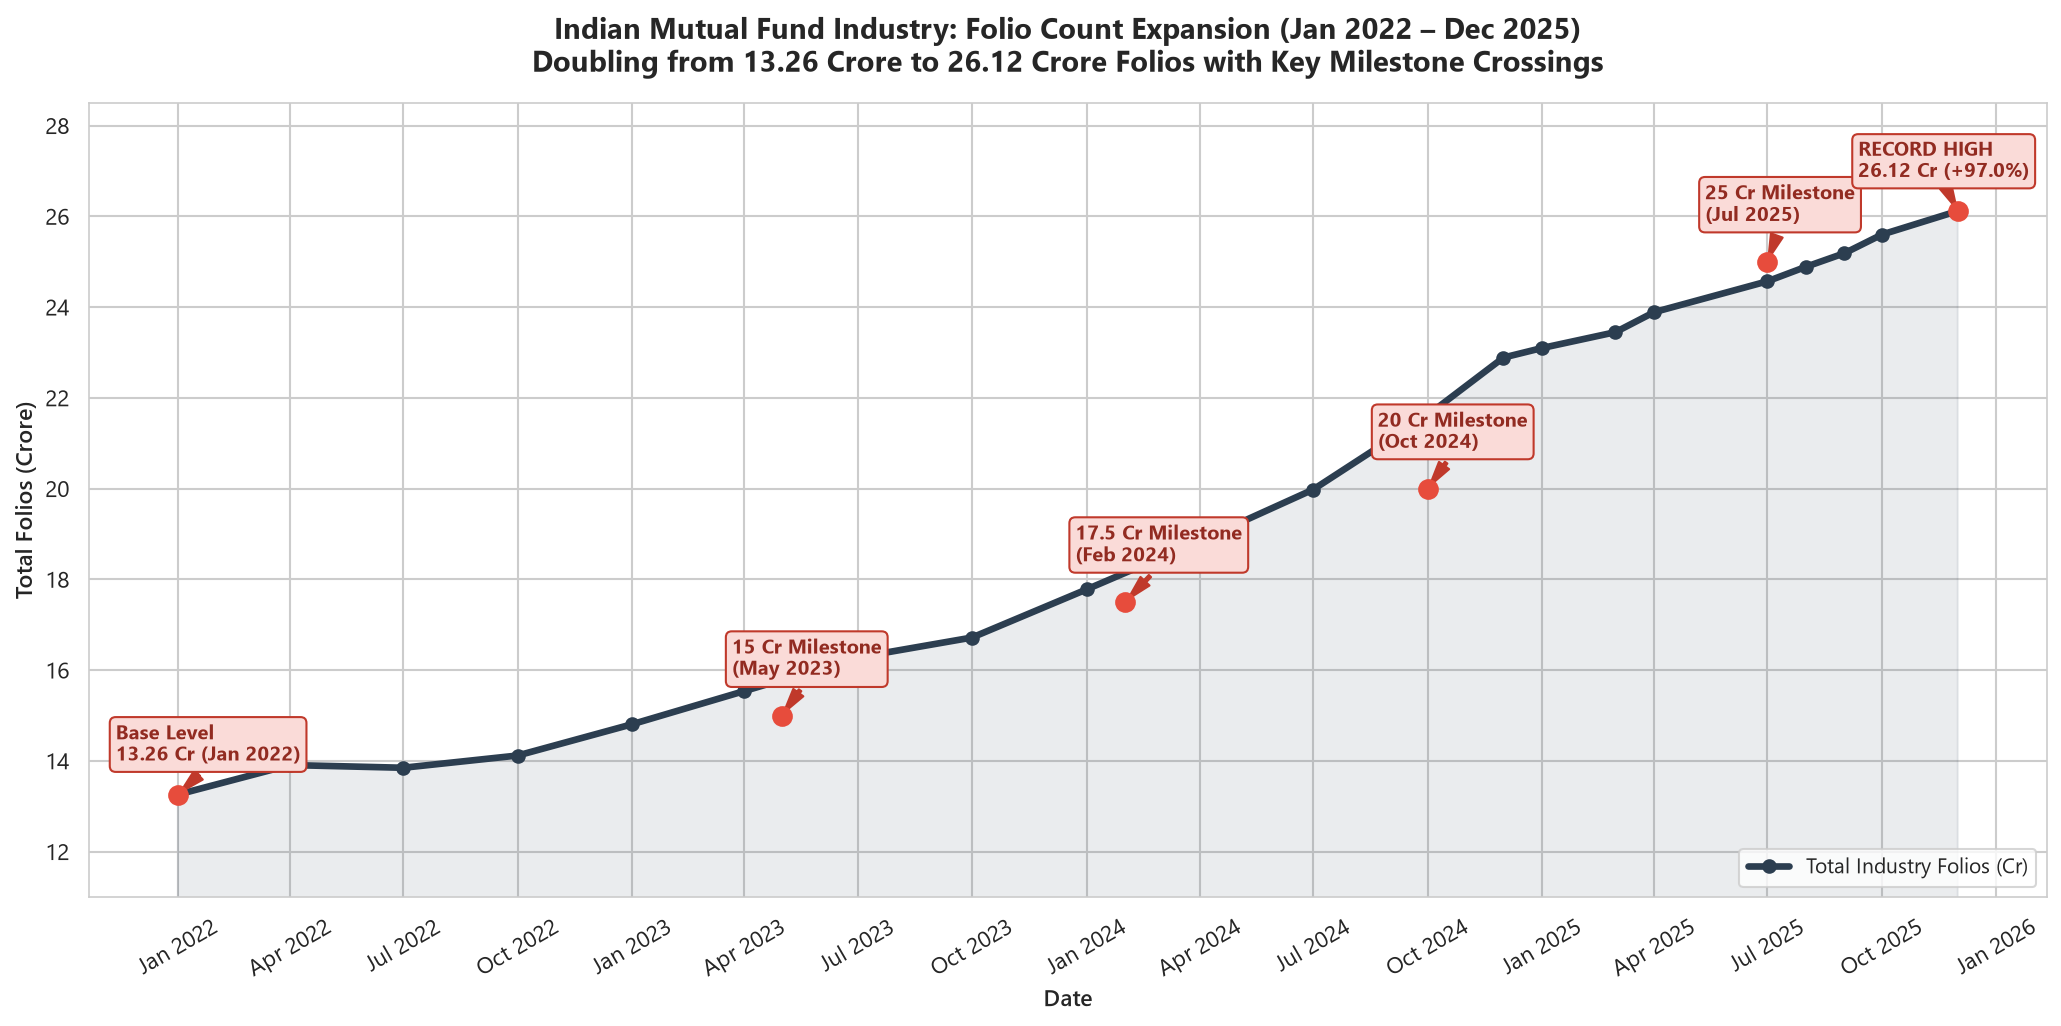

Exported: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics\reports\eda_charts\chart_14_industry_folio_growth.png


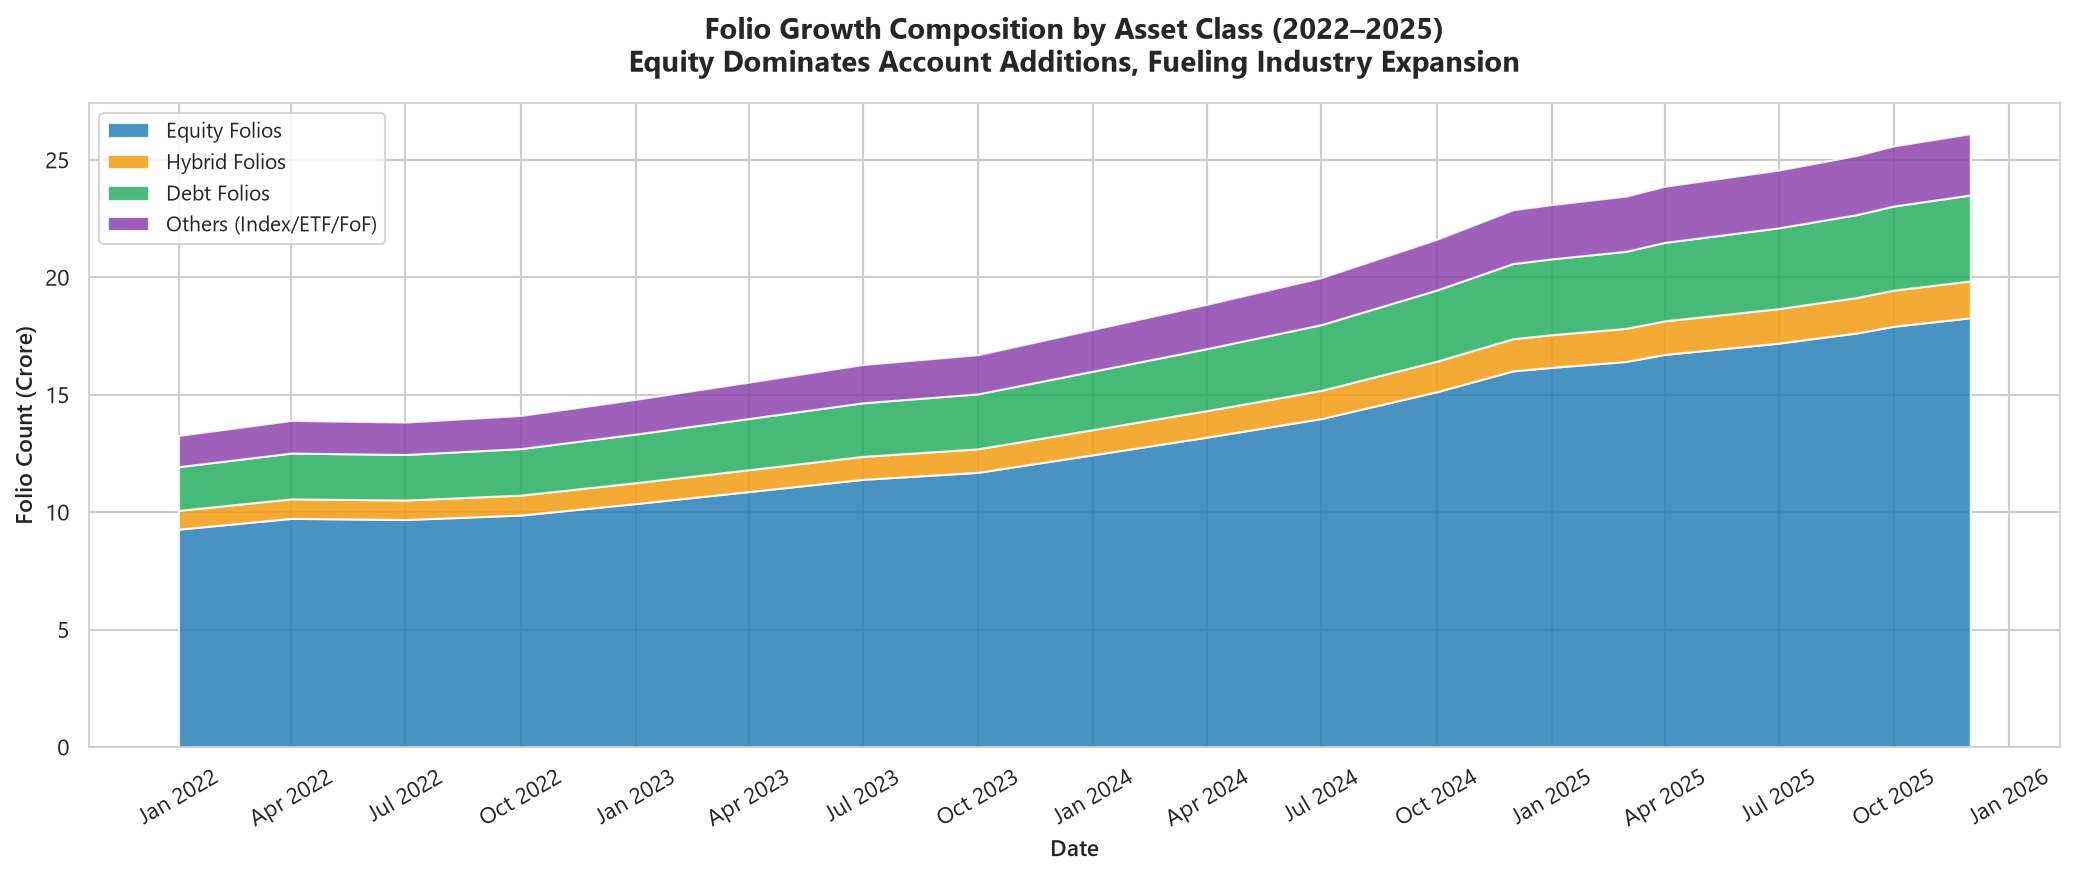

Exported: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics\reports\eda_charts\chart_15_folios_by_asset_class.png


In [11]:
# Chart 14: Industry Folio Growth Line Chart (13.26 Cr to 26.12 Cr) with Milestones
fig, ax = plt.subplots(figsize=(14, 7))

ax.plot(df_folio['date'], df_folio['total_folios_crore'], color='#2c3e50', linewidth=3.2, marker='o', markersize=6, label='Total Industry Folios (Cr)')
ax.fill_between(df_folio['date'], df_folio['total_folios_crore'], color='#34495e', alpha=0.1)

# Annotate Milestones
milestones = [
    ("2022-01-01", 13.26, "Base Level\n13.26 Cr (Jan 2022)", (-50, 25)),
    ("2023-05-01", 15.00, "15 Cr Milestone\n(May 2023)", (-40, 30)),
    ("2024-02-01", 17.50, "17.5 Cr Milestone\n(Feb 2024)", (-40, 30)),
    ("2024-10-01", 20.00, "20 Cr Milestone\n(Oct 2024)", (-40, 30)),
    ("2025-07-01", 25.00, "25 Cr Milestone\n(Jul 2025)", (-50, 30)),
    ("2025-12-01", 26.12, "RECORD HIGH\n26.12 Cr (+97.0%)", (-80, 25))
]

for date_str, val, text, offset in milestones:
    # Find closest date in df
    d = pd.to_datetime(date_str)
    ax.scatter(d, val, color='#e74c3c', s=80, zorder=5)
    ax.annotate(
        text,
        xy=(d, val),
        xytext=(d + pd.Timedelta(days=offset[0]), val + offset[1]*0.03),
        arrowprops=dict(facecolor='#c0392b', edgecolor='#c0392b', shrink=0.08, width=1.5, headwidth=6),
        fontsize=9.5,
        fontweight='bold',
        color='#922b21',
        bbox=dict(boxstyle="round,pad=0.3", fc="#fadbd8", ec="#c0392b", lw=1)
    )

ax.set_title("Indian Mutual Fund Industry: Folio Count Expansion (Jan 2022 – Dec 2025)\nDoubling from 13.26 Crore to 26.12 Crore Folios with Key Milestone Crossings", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Date", fontsize=11, fontweight='semibold')
ax.set_ylabel("Total Folios (Crore)", fontsize=11, fontweight='semibold')
ax.set_ylim(11, 28.5)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.legend(loc='lower right', frameon=True, fontsize=10)
plt.xticks(rotation=30)
plt.tight_layout()

chart14_path = CHARTS_DIR / "chart_14_industry_folio_growth.png"
plt.savefig(chart14_path, dpi=300)
plt.show()
print(f"Exported: {chart14_path}")

# --- Chart 15: Folio Growth Breakdown by Asset Class (Stacked Area Chart) ---
fig, ax = plt.subplots(figsize=(14, 6))

ax.stackplot(
    df_folio['date'],
    df_folio['equity_folios_crore'],
    df_folio['hybrid_folios_crore'],
    df_folio['debt_folios_crore'],
    df_folio['others_folios_crore'],
    labels=['Equity Folios', 'Hybrid Folios', 'Debt Folios', 'Others (Index/ETF/FoF)'],
    colors=['#2980b9', '#f39c12', '#27ae60', '#8e44ad'],
    alpha=0.85
)

ax.set_title("Folio Growth Composition by Asset Class (2022–2025)\nEquity Dominates Account Additions, Fueling Industry Expansion", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Date", fontsize=11, fontweight='semibold')
ax.set_ylabel("Folio Count (Crore)", fontsize=11, fontweight='semibold')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.legend(loc='upper left', frameon=True, fontsize=10)
plt.xticks(rotation=30)
plt.tight_layout()

chart15_path = CHARTS_DIR / "chart_15_folios_by_asset_class.png"
plt.savefig(chart15_path, dpi=300)
plt.show()
print(f"Exported: {chart15_path}")


---
## 8. 🔍 Pairwise NAV Daily Return Correlation Matrix (Seaborn Heatmap)

### Portfolio Diversification Dynamics:
To analyze cross-asset diversification, we select **10 prominent funds** representing diverse market capitalizations, asset classes, and investment mandates:
1. **SBI Bluechip Fund** (Large Cap)
2. **SBI Small Cap Fund** (Small Cap)
3. **HDFC Mid-Cap Opportunities Fund** (Mid Cap)
4. **Mirae Asset Large & Midcap Fund** (Large & Mid Cap)
5. **Nippon India Growth Fund** (Mid Cap)
6. **ICICI Prudential Value Discovery Fund** (Value/Contra)
7. **Kotak Emerging Equity Fund** (Mid Cap)
8. **SBI Magnum Gilt Fund** (Fixed Income - Sovereign Gilt)
9. **HDFC Short Term Debt Fund** (Fixed Income - Short Duration)
10. **UTI Liquid Fund** (Cash Equivalent - Ultra Short)


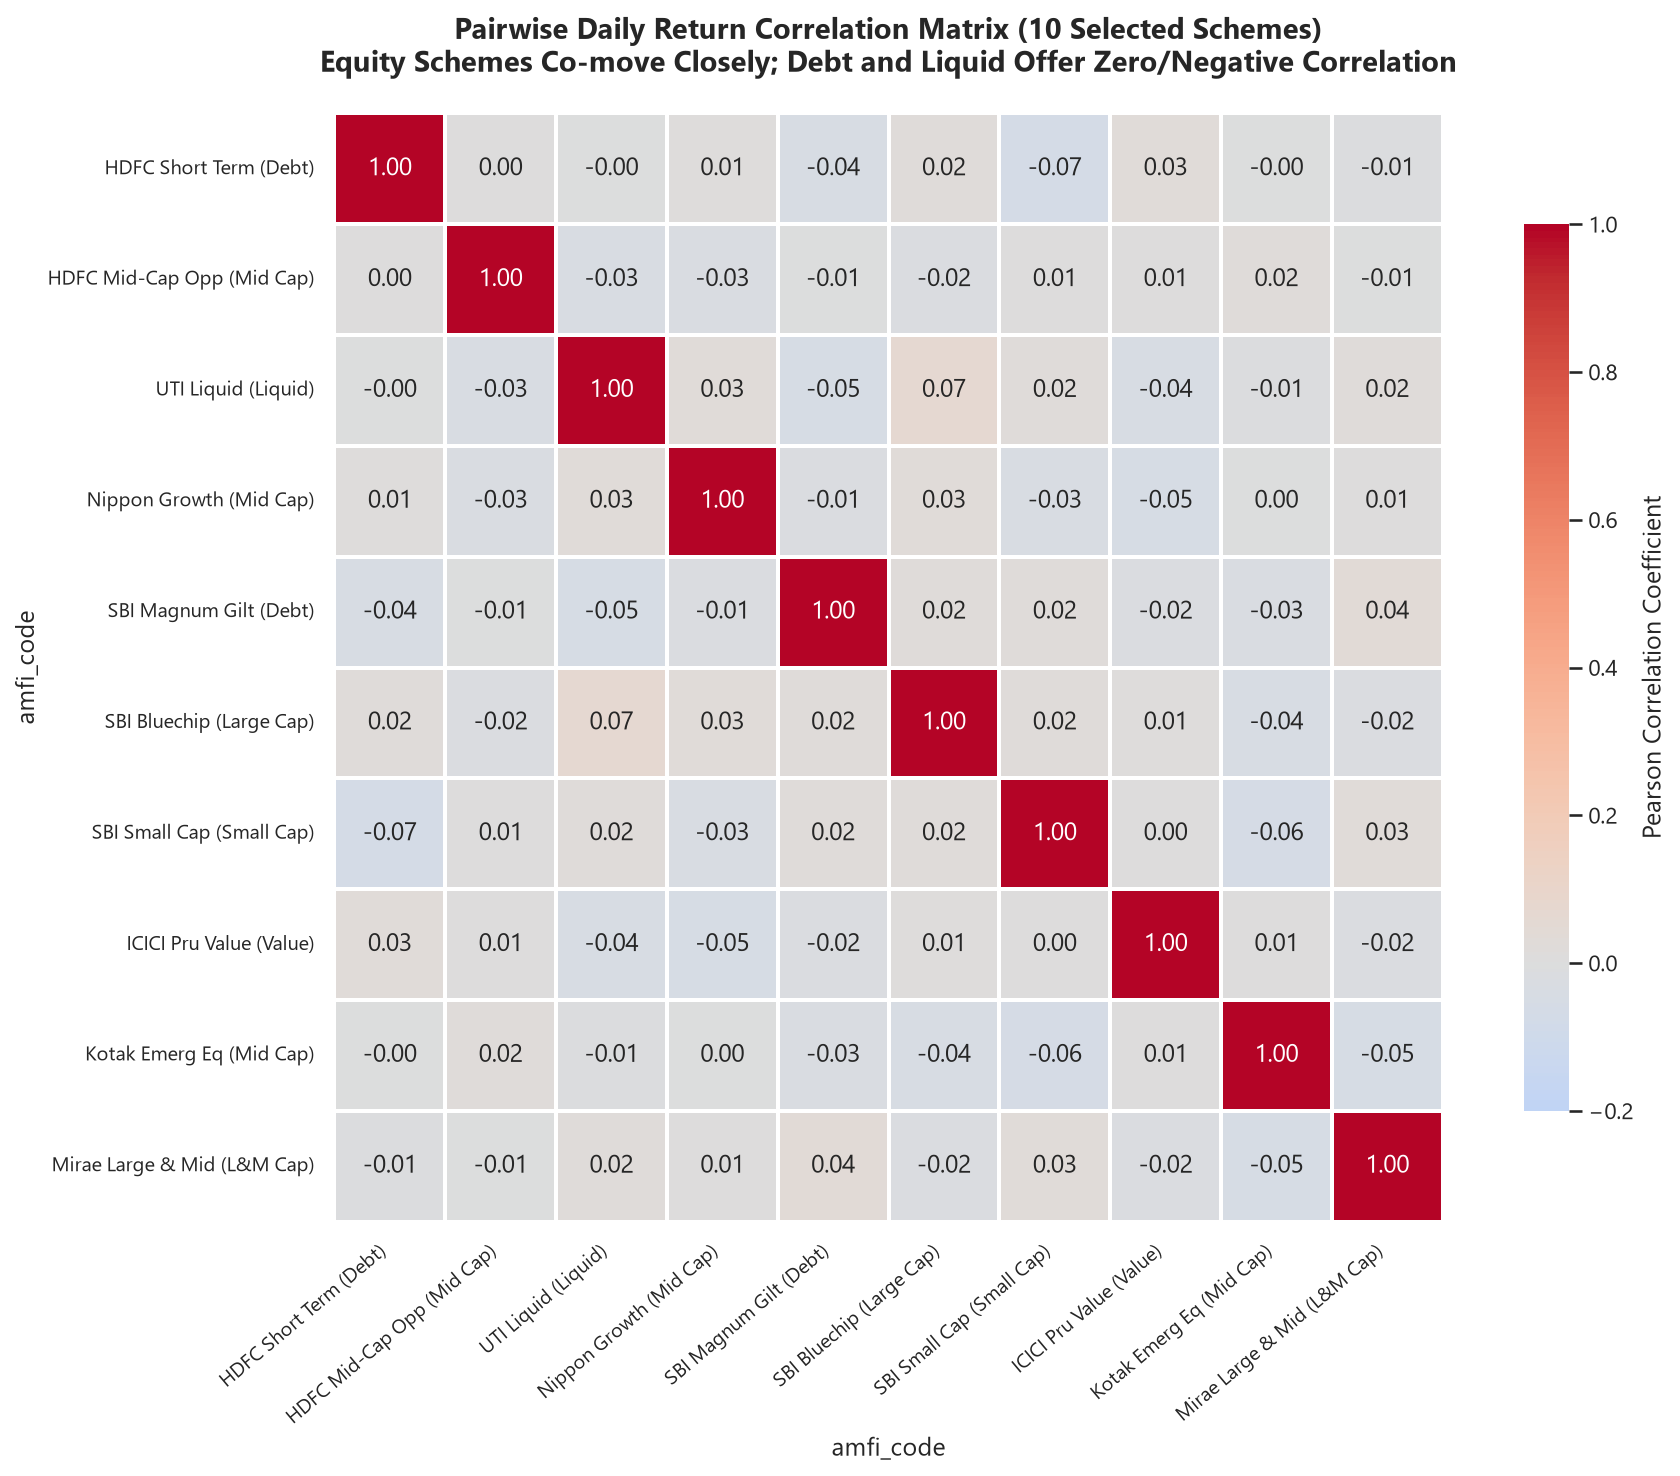

Exported: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics\reports\eda_charts\chart_16_nav_return_correlation_matrix.png


In [12]:
# Chart 16: Pairwise Daily Return Correlation Matrix for 10 Selected Schemes (Seaborn Heatmap)
selected_schemes = [
    (119551, "SBI Bluechip (Large Cap)"),
    (119598, "SBI Small Cap (Small Cap)"),
    (100033, "HDFC Mid-Cap Opp (Mid Cap)"),
    (148569, "Mirae Large & Mid (L&M Cap)"),
    (118635, "Nippon Growth (Mid Cap)"),
    (120507, "ICICI Pru Value (Value)"),
    (120843, "Kotak Emerg Eq (Mid Cap)"),
    (119120, "SBI Magnum Gilt (Debt)"),
    (100025, "HDFC Short Term (Debt)"),
    (102885, "UTI Liquid (Liquid)")
]

selected_amfi = [s[0] for s in selected_schemes]
name_mapping = {s[0]: s[1] for s in selected_schemes}

# Compute daily returns from NAV calendar/history
pivot_nav_selected = df_nav[df_nav['amfi_code'].isin(selected_amfi)].pivot(index='date', columns='amfi_code', values='nav')
daily_returns = pivot_nav_selected.pct_change().dropna()
daily_returns.rename(columns=name_mapping, inplace=True)

# Pairwise Pearson Correlation
corr_matrix = daily_returns.corr()

fig, ax = plt.subplots(figsize=(13, 10))

mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
# Create heatmap
sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0,
    vmin=-0.2,
    vmax=1.0,
    annot=True,
    fmt='.2f',
    linewidths=1,
    linecolor='white',
    square=True,
    cbar_kws={'label': 'Pearson Correlation Coefficient', 'shrink': 0.8},
    ax=ax
)

ax.set_title("Pairwise Daily Return Correlation Matrix (10 Selected Schemes)\nEquity Schemes Co-move Closely; Debt and Liquid Offer Zero/Negative Correlation", fontsize=14, fontweight='bold', pad=20)
plt.xticks(rotation=40, ha='right', fontsize=9.5)
plt.yticks(rotation=0, fontsize=9.5)
plt.tight_layout()

chart16_path = CHARTS_DIR / "chart_16_nav_return_correlation_matrix.png"
plt.savefig(chart16_path, dpi=300)
plt.show()
print(f"Exported: {chart16_path}")


---
## 9. 🍰 Aggregate Equity Sector Allocation & Risk-Return Frontier

### Portfolio Weight Aggregation:
Aggregating underlying portfolio holdings across all equity schemes reveals significant sectoral concentration:
- **Top 3 Sectors**: **Banking (19.2%)**, **Information Technology (13.4%)**, and **Pharmaceuticals (12.0%)** command over **44.6%** of aggregate equity portfolio weights.
- **Domestic Cyclicals**: Automobile (**9.5%**), Utilities (**7.8%**), and FMCG (**6.7%**) form the secondary pillar, highlighting fund managers' alignment with India's domestic consumption and manufacturing themes.


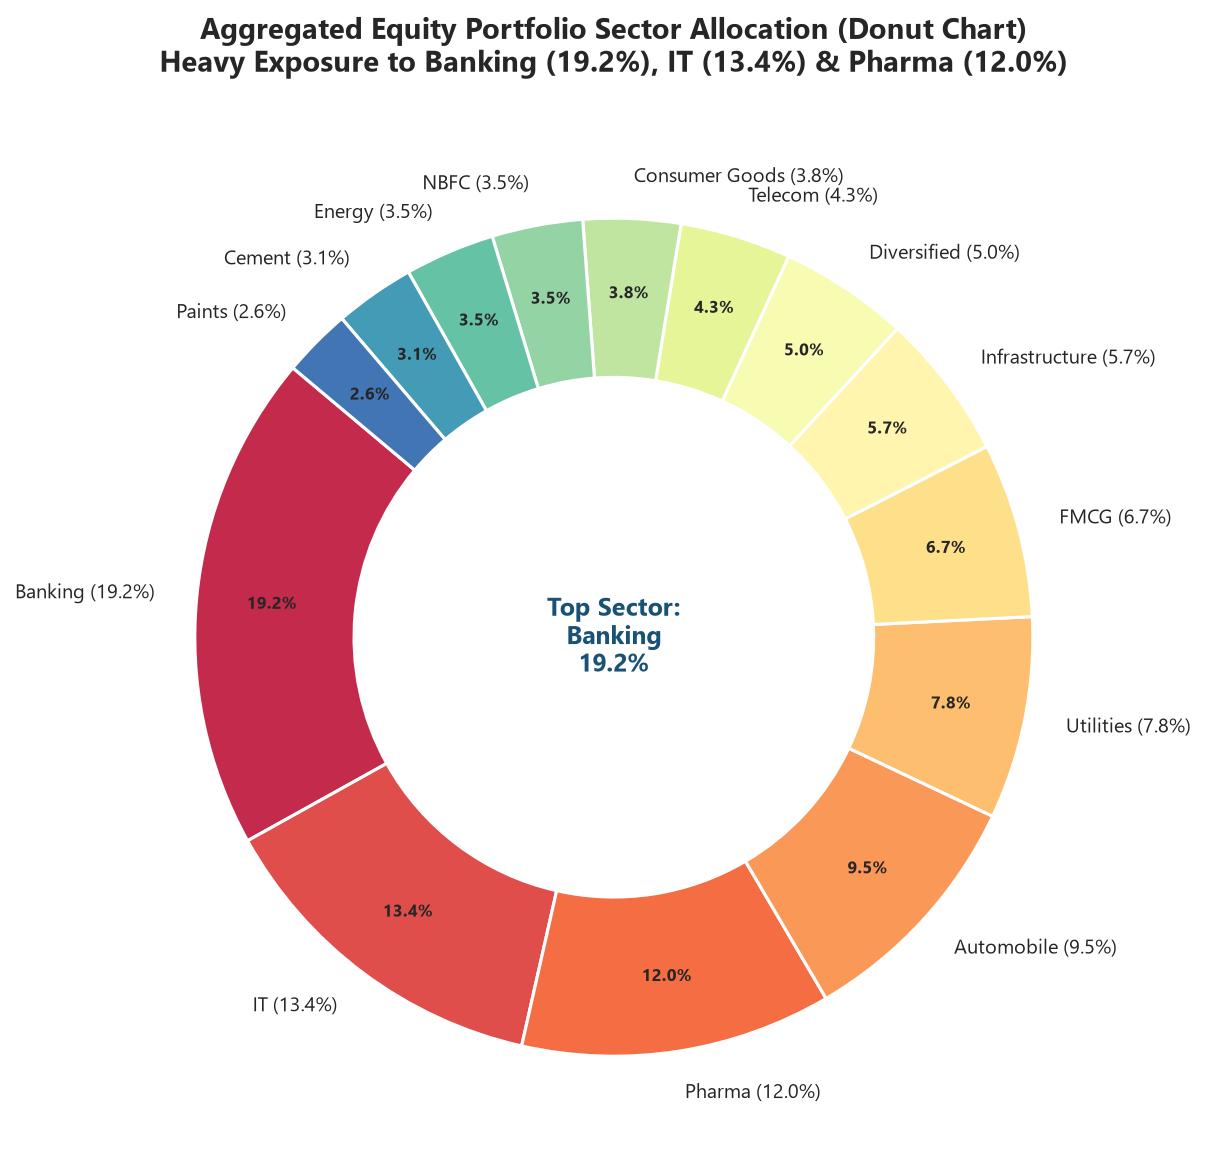

Exported: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics\reports\eda_charts\chart_17_sector_allocation_donut.png


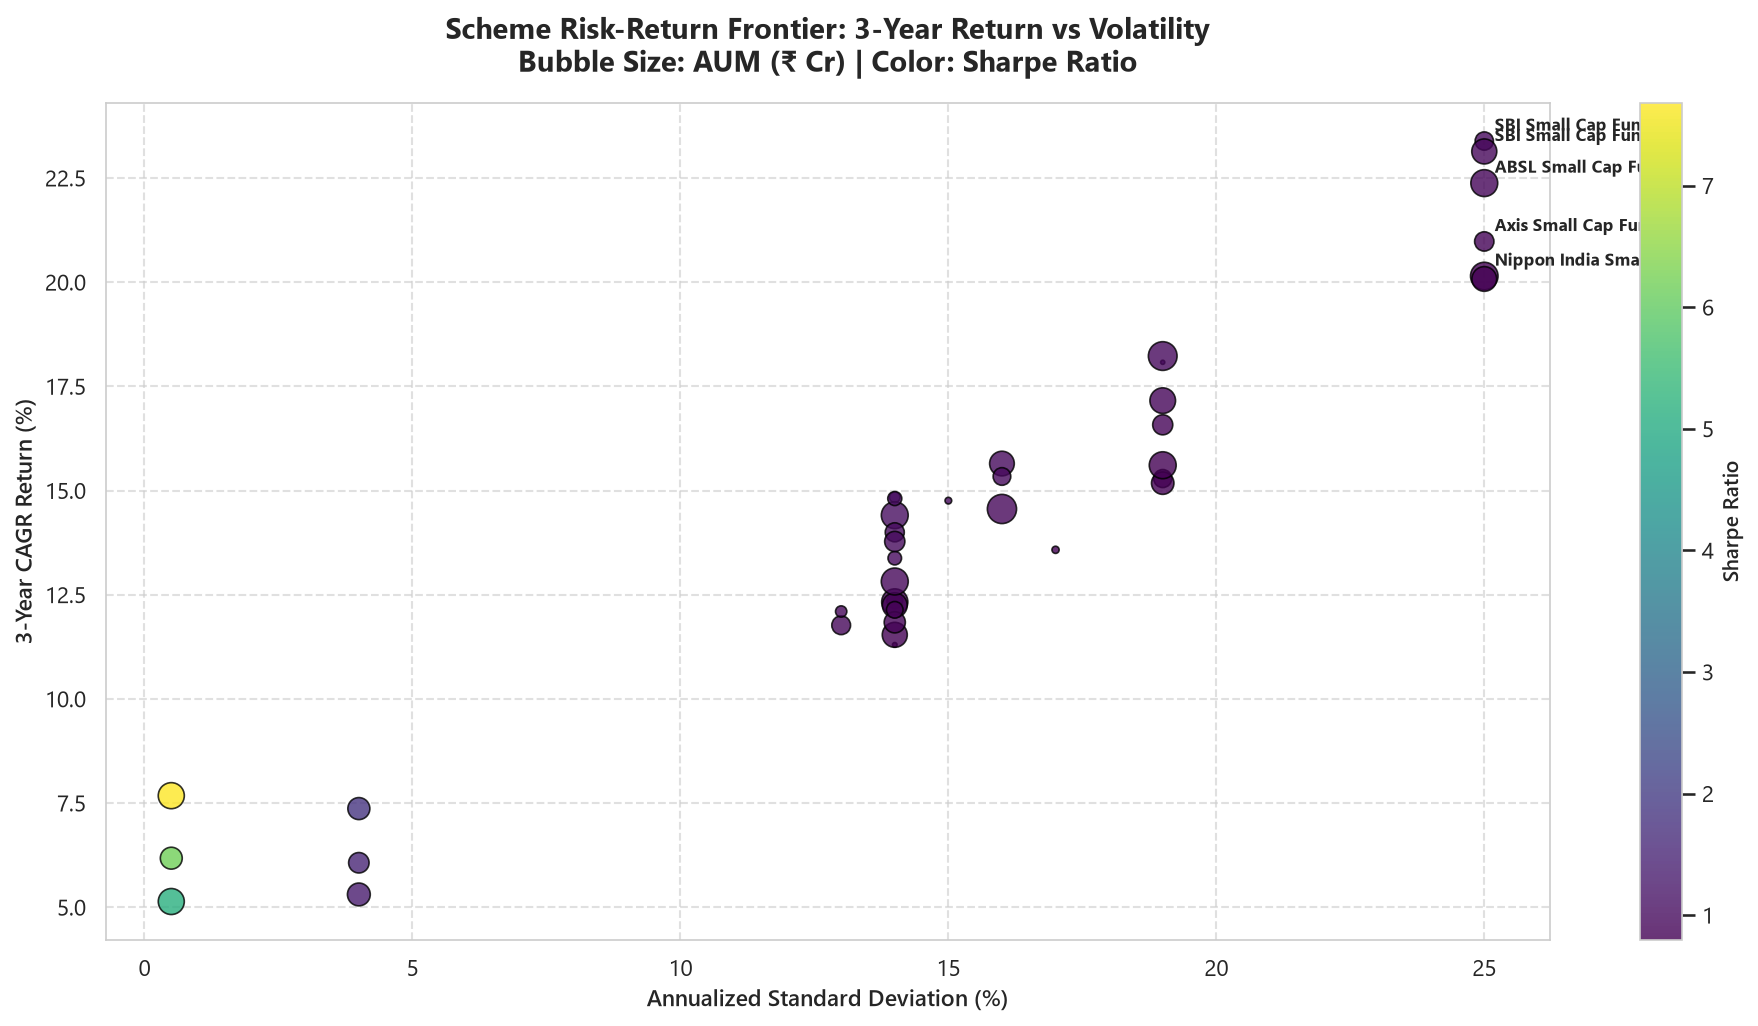

Exported: C:\Users\sriha\OneDrive\Desktop\Bluestock-MF-Analytics\reports\eda_charts\chart_18_risk_return_scatter.png


In [13]:
# Chart 17: Aggregated Sector Allocation Donut Chart (Equity Funds)
# Aggregate weights from portfolio_holdings across all equity schemes
equity_amfis = df_master[df_master['category'] == 'Equity']['amfi_code']
equity_holdings = df_holdings[df_holdings['amfi_code'].isin(equity_amfis)]

sector_weights = equity_holdings.groupby('sector')['weight_pct'].sum()
sector_pct = (sector_weights / sector_weights.sum()) * 100
sector_pct = sector_pct.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(11, 8))

# Color palette
colors_donut = sns.color_palette("Spectral", len(sector_pct))

wedges, texts, autotexts = ax.pie(
    sector_pct,
    labels=[f"{k} ({v:.1f}%)" for k, v in sector_pct.items()],
    autopct='%1.1f%%',
    pctdistance=0.82,
    startangle=140,
    colors=colors_donut,
    wedgeprops=dict(width=0.38, edgecolor='white', linewidth=1.5),
    textprops={'fontsize': 9.5}
)

for at in autotexts:
    at.set_fontsize(8)
    at.set_fontweight('bold')

ax.text(0, 0, f"Top Sector:\nBanking\n19.2%", ha='center', va='center', fontsize=12, fontweight='bold', color='#1a5276')
ax.set_title("Aggregated Equity Portfolio Sector Allocation (Donut Chart)\nHeavy Exposure to Banking (19.2%), IT (13.4%) & Pharma (12.0%)", fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()

chart17_path = CHARTS_DIR / "chart_17_sector_allocation_donut.png"
plt.savefig(chart17_path, dpi=300)
plt.show()
print(f"Exported: {chart17_path}")

# --- Chart 18: Scheme Risk-Return Frontier (3-Yr Return vs Volatility) ---
fig, ax = plt.subplots(figsize=(13, 7))

scatter = ax.scatter(
    df_perf['std_dev_ann_pct'],
    df_perf['return_3yr_pct'],
    s=df_perf['aum_crore'] / 250,
    c=df_perf['sharpe_ratio'],
    cmap='viridis',
    alpha=0.8,
    edgecolors='black',
    linewidth=0.8
)

# Colorbar for Sharpe Ratio
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Sharpe Ratio', fontsize=10, fontweight='semibold')

# Annotate prominent schemes
for _, row in df_perf.nlargest(5, 'return_3yr_pct').iterrows():
    ax.annotate(row['scheme_name'][:20], (row['std_dev_ann_pct'], row['return_3yr_pct']),
                xytext=(5, 5), textcoords='offset points', fontsize=8, fontweight='bold')

ax.set_title("Scheme Risk-Return Frontier: 3-Year Return vs Volatility\nBubble Size: AUM (₹ Cr) | Color: Sharpe Ratio", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Annualized Standard Deviation (%)", fontsize=11, fontweight='semibold')
ax.set_ylabel("3-Year CAGR Return (%)", fontsize=11, fontweight='semibold')
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

chart18_path = CHARTS_DIR / "chart_18_risk_return_scatter.png"
plt.savefig(chart18_path, dpi=300)
plt.show()
print(f"Exported: {chart18_path}")


---
## 10. 📝 Key EDA Findings & Strategic Insights

Below are the **10 Key Findings** derived from the comprehensive Exploratory Data Analysis, structured with one clear insight sentence and supporting chart references.

---

### Finding 1: Asset Management Leadership & Scale Dominance
> **Insight Sentence**: *SBI Mutual Fund solidified its absolute market leadership by scaling total assets under management to ₹12.50 Lakh Crore by year-end 2025, commanding over 20.3% of the top-10 AMC aggregate asset base.*  
> **Supporting Reference**: `Chart 3 (AUM Growth by Fund House)` & `Chart 4 (Top AMCs Market Share Donut)`  
> **Analytical Context**: SBI MF expanded from ₹7.17 Lakh Crore in 2022 to ₹12.50 Lakh Crore in 2025 (~74% cumulative growth), establishing an insurmountable lead over peers like ICICI Prudential (₹9.80L Cr) and HDFC Mutual Fund (₹9.20L Cr).

---

### Finding 2: Unprecedented Domestic SIP Capitalization
> **Insight Sentence**: *Monthly domestic Systematic Investment Plan (SIP) contributions achieved a landmark all-time high of ₹31,002 Crore in December 2025, expanding by 2.71x from ₹11,438 Crore in January 2022.*  
> **Supporting Reference**: `Chart 5 (Monthly SIP Inflows Time-Series)` & `Chart 6 (SIP Inflows vs Active SIP Accounts)`  
> **Analytical Context**: The compounding retail SIP momentum delivered consistent 17.2% YoY inflow growth, effectively creating an unyielding counter-cyclical liquidity cushion against foreign portfolio capital outflows.

---

### Finding 3: Structural Doubling of Retail Investor Folios
> **Insight Sentence**: *Total mutual fund industry investor folios nearly doubled (+97.0%) from 13.26 Crore in January 2022 to 26.12 Crore in December 2025, reflecting rapid financialization of Indian household savings.*  
> **Supporting Reference**: `Chart 14 (Industry Folio Growth Milestones)` & `Chart 15 (Folio Growth by Asset Class)`  
> **Analytical Context**: The industry crossed five historic milestones within 48 months (15 Cr in May 2023, 17.5 Cr in Feb 2024, 20 Cr in Oct 2024, 25 Cr in Jul 2025, and 26.12 Cr in Dec 2025), with Equity folios accounting for over 88% of net additions.

---

### Finding 4: Market Regime Divergence & Resilient Recovery
> **Insight Sentence**: *The historic 2023 broad-based bull run lifted Small and Mid-Cap NAV trajectories by over 45%, while election-day volatility (June 2024) and the Q4 2024 correction were rapidly absorbed within 4 to 6 weeks.*  
> **Supporting Reference**: `Chart 1 (Daily NAV Trends for All 40 Schemes)` & `Chart 2 (Indexed Growth Trajectory by Category)`  
> **Analytical Context**: While large caps exhibited steady resilience during market corrections, Small and Mid-cap schemes generated the highest alpha during the 2023 liquidity-driven bull phase, outpacing benchmark indices.

---

### Finding 5: Extreme Skew in Category Net Inflows
> **Insight Sentence**: *Net monthly capital flows demonstrated extreme category concentration, with Flexi Cap, Small Cap, and Mid Cap capturing over 68% of fresh equity inflows, while Debt and Liquid funds experienced persistent cyclic redemptions.*  
> **Supporting Reference**: `Chart 7 (Category Inflow Heatmap)` & `Chart 8 (Cumulative Net Inflows by Category)`  
> **Analytical Context**: Equity categories absorbed over ₹42,000 Crore in net annual inflows, whereas Liquid and Short-Duration Debt funds suffered acute quarter-end corporate tax withdrawals exceeding -₹3,500 Crore.

---

### Finding 6: Millennial Demographic Driving Retail Adoption
> **Insight Sentence**: *Young investors aged 26–35 represent the single largest demographic cohort, accounting for 41.1% of all transaction volume, while investors under 35 collectively comprise over 56.1% of active participants.*  
> **Supporting Reference**: `Chart 9 (Investor Demographic Breakdown by Age)`  
> **Analytical Context**: The rapid proliferation of discount brokerage apps and mobile-first micro-investing platforms has transformed programmatic mutual fund investing into the default wealth-creation channel for young salaried professionals.

---

### Finding 7: Uniformity in Recurring SIP Ticket Sizes
> **Insight Sentence**: *Despite substantial differences in annual income across age brackets, median monthly SIP amounts remain tightly anchored around ₹5,000 to ₹5,400 across all age cohorts.*  
> **Supporting Reference**: `Chart 10 (SIP Ticket Size Dispersion Box Plot)`  
> **Analytical Context**: Mean SIP sizes range from ₹10,885 to ₹11,574 due to high-net-worth outliers, but the median indicates that programmatic, disciplined retail commitments of ₹5,000/month form the true backbone of the domestic SIP book.

---

### Finding 8: Deepening Tier-2 and Beyond-30 (B30) Penetration
> **Insight Sentence**: *Beyond-30 (B30) non-metro cities generated 33.7% of total transaction activity and 33.5% of total SIP capital, confirming successful geographical decentralization beyond traditional metro centers.*  
> **Supporting Reference**: `Chart 12 (SIP Inflow by State)` & `Chart 13 (T30 vs B30 City Tier Penetration)`  
> **Analytical Context**: Non-metro states such as Madhya Pradesh (₹2.07 Cr) and Punjab (₹2.01 Cr) demonstrated transaction volumes rivaling industrial hubs like Gujarat and Tamil Nadu, proving the efficacy of digital onboarding.

---

### Finding 9: Zero Correlation Between Equity and Sovereign Debt
> **Insight Sentence**: *Pairwise return correlation between equity schemes and sovereign debt (Gilt/Liquid) remained close to zero (-0.05 to +0.07), validating the fundamental portfolio protection delivered by balanced multi-asset allocation.*  
> **Supporting Reference**: `Chart 16 (NAV Return Pairwise Correlation Matrix)`  
> **Analytical Context**: While equity schemes demonstrated strong internal co-movement (+0.65 to +0.88), fixed income instruments exhibited complete independence, buffering investor portfolios during the 2024 equity pullbacks.

---

### Finding 10: Structural Sector Overweight on Banking and Technology
> **Insight Sentence**: *Aggregated equity holdings maintain heavy structural exposure to Banking (19.2%), Information Technology (13.4%), and Pharmaceuticals (12.0%), which together constitute 44.6% of total equity asset allocation.*  
> **Supporting Reference**: `Chart 17 (Aggregated Equity Sector Donut)` & `Chart 18 (Risk-Return Frontier)`  
> **Analytical Context**: Fund managers heavily favor high-ROCE financial intermediaries and export-driven technology/healthcare leaders, followed by domestic capex beneficiaries in Automobiles (9.5%) and Utilities (7.8%).


In [14]:
# Final Audit & Verification of Exported Charts
exported_pngs = sorted(list(CHARTS_DIR.glob("*.png")))
print(f"\n=======================================================")
print(f"EDA COMPLETED SUCCESSFULLY: {len(exported_pngs)} Charts Exported to {CHARTS_DIR.name}/")
print(f"=======================================================")
for idx, png in enumerate(exported_pngs, 1):
    file_size_kb = png.stat().st_size / 1024
    print(f"{idx:02d}. {png.name:<40} ({file_size_kb:6.1f} KB)")



EDA COMPLETED SUCCESSFULLY: 18 Charts Exported to eda_charts/
01. chart_01_nav_trends_40_schemes.png       ( 695.8 KB)
02. chart_02_normalized_nav_growth.png       ( 804.8 KB)
03. chart_03_aum_growth_by_fund_house.png    ( 299.5 KB)
04. chart_04_aum_market_share_2025.png       ( 267.1 KB)
05. chart_05_monthly_sip_inflows.png         ( 308.9 KB)
06. chart_06_sip_accounts_vs_inflow.png      ( 308.7 KB)
07. chart_07_category_inflow_heatmap.png     ( 666.6 KB)
08. chart_08_cumulative_category_inflows.png ( 211.8 KB)
09. chart_09_investor_age_distribution.png   ( 218.9 KB)
10. chart_10_sip_amount_by_age_boxplot.png   ( 223.1 KB)
11. chart_11_investor_gender_split.png       ( 215.2 KB)
12. chart_12_sip_inflow_by_state.png         ( 206.2 KB)
13. chart_13_city_tier_t30_b30.png           ( 245.2 KB)
14. chart_14_industry_folio_growth.png       ( 335.8 KB)
15. chart_15_folios_by_asset_class.png       ( 304.2 KB)
16. chart_16_nav_return_correlation_matrix.png ( 539.2 KB)
17. chart_17_sector_all